In [2]:
!pip install pyclustering

     ---------------------------------------- 0.0/2.6 MB ? eta -:--:--
     ------------ --------------------------- 0.8/2.6 MB 5.6 MB/s eta 0:00:01
     -------------------------------- ------- 2.1/2.6 MB 5.6 MB/s eta 0:00:01
     ---------------------------------------- 2.6/2.6 MB 5.3 MB/s eta 0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for pyclustering: filename=pyclustering-0.10.1.2-py3-none-any.whl size=2395132 sha256=be321dc16b462ae07dd04251ca9a40a0de51abec3c4c38e47a1278ee7fcf3d79
  Stored in directory: c:\users\panos\appdata\local\pip\cache\wheels\68\29\b4\131bd7deec3663cc311ab9aa64d6517c3e3ec24bcadfc32f74
Successfully built pyclustering


In [4]:
#libraries

import warnings
import numpy as np
np.warnings = warnings

import os
import csv
import pandas as pd
import tensorflow as tf
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import silhouette_score
from collections import Counter, defaultdict
from sklearn.preprocessing import LabelEncoder
from pyclustering.cluster.kmeans import kmeans
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.applications import ResNet50
from sklearn.manifold import LocallyLinearEmbedding
from sklearn.metrics.pairwise import cosine_distances
from sklearn.cluster import KMeans, AgglomerativeClustering
from pyclustering.utils.metric import distance_metric, type_metric
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from pyclustering.cluster.center_initializer import kmeans_plusplus_initializer

In [5]:
path_of_train_images = "C:/Users/panos/OneDrive/Υπολογιστής/Πανεπιστημιο/Machine Learning/project2_5053_5075/train-images/train"

# φόρτωση εικόνων εκπαίδευσης από τους φακέλους "pleasant" και "unpleasant"
images, labels = [], []

for expression in ["unpleasant", "pleasant"]:
    folder = os.path.join(path_of_train_images, expression) 

    # filenames = os.listdir(folder) # ετσι φορτώνονται ολες οι train eikones
    filenames = os.listdir(folder)
    for filename in filenames:
        img_path = os.path.join(folder, filename)
        img = load_img(img_path, target_size=(64, 64)) #μεγεθος καθε εικονας 64x64
                                                      
        images.append(img_to_array(img))
        labels.append(expression)

x = np.array(images) / 255.0  # τιμες φωτεινοτητας απο 0 εως 255 (κανονικοποιηση τιμων pixel)

y = np.array(labels) 
# μετατροπή των ετικετών κειμένου ("unpleasant", "pleasant") σε αριθμητικές τιμές (0 και 1)
y = LabelEncoder().fit_transform(y)

In [8]:
# Ελεγχος

print (x.shape)  # 6376 "train" εικόνες 64x64 με 3 κανάλια χρώματος(R,G,B)
# τιμη x ειναι απο 0 εως 255

print (y.shape) # 6376 "train" εικόνες, έχουμε μία ετικέτα (0 ή 1) για κάθε εικόνα
# τιμη y ειναι 0 ή 1

(6376, 64, 64, 3)
(6376,)


In [10]:
# Εξαγωγη χαρακτηριστικων απο το συνολο εικονων με χρηση του ResNet50 (pretrained CNN)

# φόρτωση του pretrained μοντελου ResNet50 χωρις τα τελικα classification layers
resnet = ResNet50(weights="imagenet", include_top=False, input_shape=(64, 64, 3))
                                                       
resnet.trainable = False
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()

# προεπεξεργασια των εικονων εκπαιδευσης για να ειναι συμβατες με το ResNet50
x = preprocess_input(x)                                
feature_map = resnet.predict(x)  # εξαγωγη χαρακτηριστικων απο το ResNet50
x = global_average_layer(feature_map).numpy()  # μετατροπη του σχηματος απο (n, 64, 64, 3) σε (n, 2048)         


200/200 ━━━━━━━━━━━━━━━━━━━━ 64s 305ms/step


In [12]:
# Ελεγχος

print (x.shape)  # 6376 "train" εικόνες, κάθε εικόνα θα γίνει διάνυσμα με 2048 στοιχεία

print (y.shape) # 6376 "train" εικόνες, έχουμε μία ετικέτα (0 ή 1) για κάθε εικόνα


(6376, 2048)
(6376,)


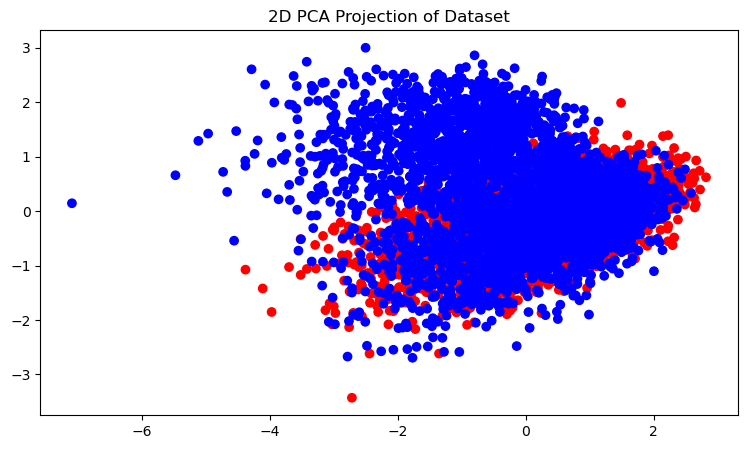

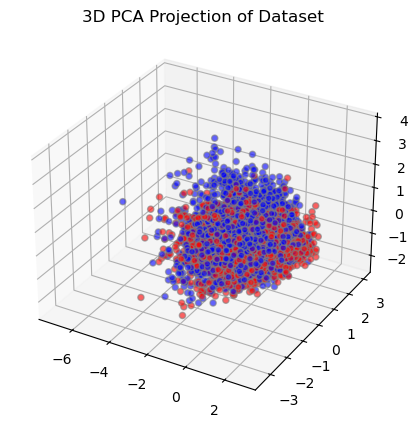

In [14]:
# PCA (Ανάλυση Πρωτευουσών Συνιστωσών)

pca_2d = PCA(n_components=2) # δημιουργούμε PCA με Μ=2 συνιστώσες
x_pca_2d = pca_2d.fit_transform(x) # τα δεδομένα μειωμένης διάστασης (2D)

plt.figure(figsize=(9, 5)) 
plt.scatter(x_pca_2d[:, 0], x_pca_2d[:, 1], c=y, cmap='bwr') # y= 0 ή 1
plt.title('2D PCA Projection of Dataset')
plt.show()

pca_3d = PCA(n_components=3) # δημιουργούμε PCA με Μ=3 συνιστώσες
x_pca_3d = pca_3d.fit_transform(x) 

fig_pca_3d = plt.figure(figsize=(9, 5))
ax = fig_pca_3d.add_subplot(111, projection='3d')
ax.scatter(x_pca_3d[:, 0], x_pca_3d[:, 1], x_pca_3d[:, 2], c=y, cmap='bwr', alpha=0.6, edgecolor='gray') 
ax.set_title('3D PCA Projection of Dataset')
plt.show()


pca_5d = PCA(n_components=5)
x_pca_5d = pca_5d.fit_transform(x) 


pca_10d = PCA(n_components=10)
x_pca_10d = pca_10d.fit_transform(x)


pca_20d = PCA(n_components=20)
x_pca_20d = pca_20d.fit_transform(x)


In [16]:
# Έλεγχος

print(x_pca_2d.shape) # 6376 "train" εικόνες, κάθε εικόνα(διάνυσμα) έχει νέα διάσταση(Μ=2)

print (y.shape) # 6376 "train" εικόνες, έχουμε μία ετικέτα (0 ή 1) για κάθε εικόνα

(6376, 2)
(6376,)


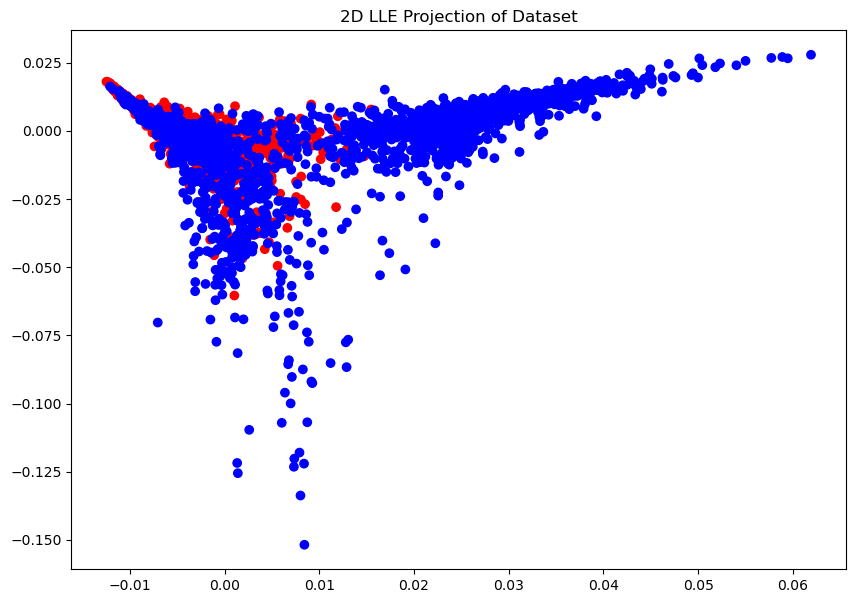

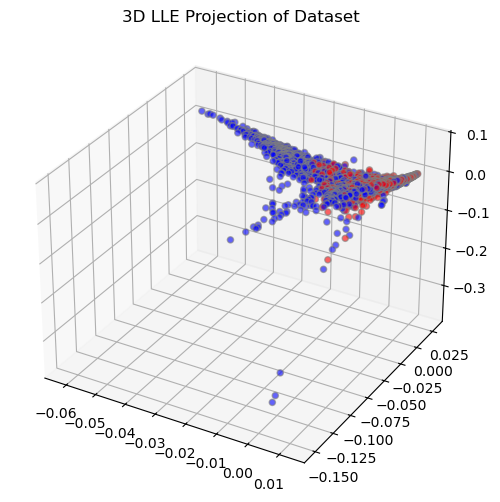

In [18]:
# LLE (Τοπική Γραμμική Ενσωμάτωση)

lle_2d = LocallyLinearEmbedding(n_components=2, n_neighbors=12) # δημιουργούμε LLE με Μ=2 συνιστώσες 
x_lle_2d = lle_2d.fit_transform(x) 

plt.figure(figsize=(10, 7)) 
plt.scatter(x_lle_2d[:, 0], x_lle_2d[:, 1], c=y, cmap='bwr') # y= 0 ή 1
plt.title('2D LLE Projection of Dataset')
plt.show()


lle_3d = LocallyLinearEmbedding(n_components=3, n_neighbors=12) # δημιουργούμε LLE με Μ=3 συνιστώσες 
x_lle_3d = lle_3d.fit_transform(x)

fig_lle_3d = plt.figure(figsize=(10, 6))
ax = fig_lle_3d.add_subplot(111, projection='3d')
ax.scatter(x_lle_3d[:, 0], x_lle_3d[:, 1], x_lle_3d[:, 2], c=y, cmap='bwr', alpha=0.6, edgecolor='gray') 
ax.set_title('3D LLE Projection of Dataset')
plt.show()


lle_5d = LocallyLinearEmbedding(n_components=5, n_neighbors=12)
x_lle_5d = lle_5d.fit_transform(x)


lle_10d = LocallyLinearEmbedding(n_components=10, n_neighbors=12)
x_lle_10d = lle_10d.fit_transform(x)


lle_20d = LocallyLinearEmbedding(n_components=20, n_neighbors=12)
x_lle_20d = lle_20d.fit_transform(x)


In [39]:
# Έλεγχος

print(x_lle_2d.shape) # 6376 "train" εικόνες, κάθε εικόνα(διάνυσμα) έχει νέα διάσταση(Μ=2)

print (y.shape) # 6376 "train" εικόνες, έχουμε μία ετικέτα (0 ή 1) για κάθε εικόνα

(6376, 2)
(6376,)


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


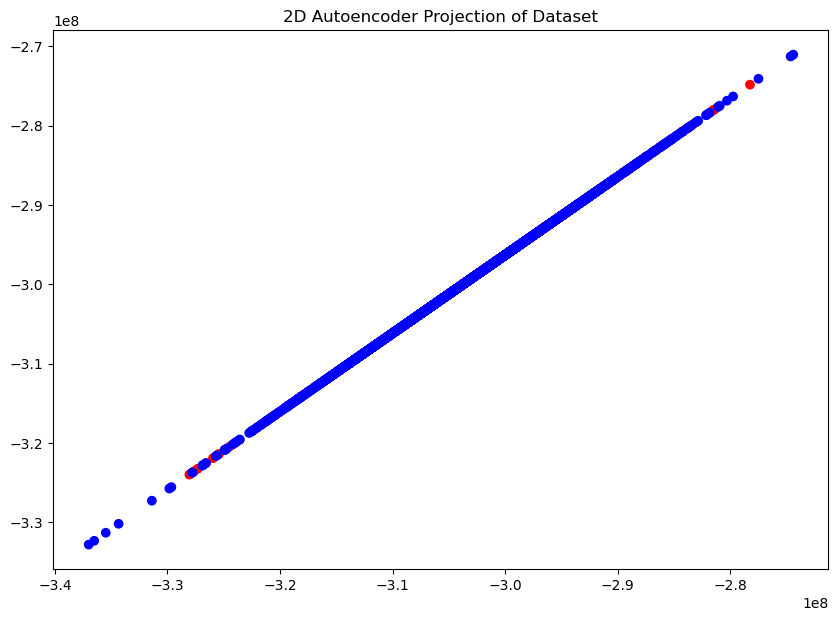

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


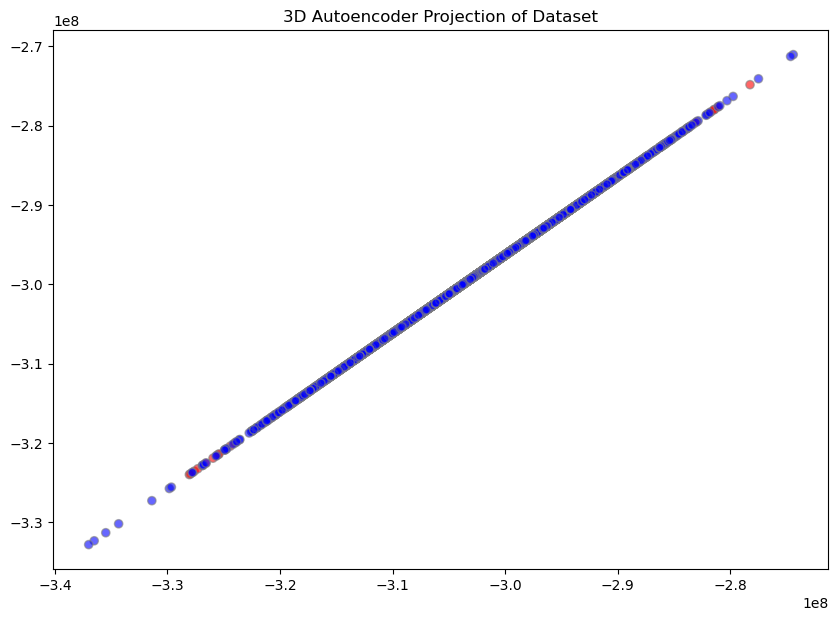

200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


In [42]:
# Autoencoder με 2 κρυφά επίπεδα: 256 και 128 νευρώνες

input_auto_2d = Input(shape=(x.shape[1],))  # Διάσταση εισόδου D=2048

encoded_2d = Dense(256, activation="relu")(input_auto_2d)  # Κρυφό επίπεδο 1
encoded_2d = Dense(128, activation="relu")(encoded_2d)  # Κρυφό επίπεδο 2

bottleneck_2d = Dense(2)(encoded_2d)  # Bottleneck layer με 2 διαστάσεις (M=2)

decoded_2d = Dense(128, activation="relu")(bottleneck_2d)  # Αντιστροφή
decoded_2d = Dense(256, activation="relu")(decoded_2d)

output_auto_2d = Dense(x.shape[1], activation="sigmoid")(decoded_2d)  # Επανακατασκευή εισόδου

# Ορισμός και εκπαίδευση autoencoder
autoencoder_2d = Model(inputs=input_auto_2d, outputs=output_auto_2d)
autoencoder_2d.compile(optimizer=Adam(), loss="binary_crossentropy")
autoencoder_2d.fit(x, x, epochs=15, verbose=0)  

# Μοντέλο encoder για εξαγωγή των μειωμένων χαρακτηριστικών
encoder_2d = Model(inputs=input_auto_2d, outputs=bottleneck_2d)
x_autoencoded_2d = encoder_2d.predict(x)


#κάνουμε οπτικοποίηση
plt.figure(figsize=(10, 7)) 
plt.scatter(x_autoencoded_2d[:, 0], x_autoencoded_2d[:, 1], c=y, cmap='bwr') 
plt.title('2D Autoencoder Projection of Dataset')
plt.show()


# Autoencoder με 2 κρυφά επίπεδα (256, 128 νευρώνες) και bottleneck 3 διαστάσεων (M=3)
input_auto_3d = Input(shape=(x.shape[1],))  # Διάσταση εισόδου D=2048
encoded_3d = Dense(256, activation="relu")(input_auto_3d)  # Κρυφό επίπεδο 1
encoded_3d = Dense(128, activation="relu")(encoded_3d)  # Κρυφό επίπεδο 2
bottleneck_3d = Dense(3)(encoded_3d)  # Bottleneck layer με 2 διαστάσεις (M=2)
decoded_3d = Dense(128, activation="relu")(bottleneck_3d)  # Αντιστροφή
decoded_3d = Dense(256, activation="relu")(decoded_3d)
output_auto_3d = Dense(x.shape[1], activation="sigmoid")(decoded_3d)  # Επανακατασκευή εισόδου

# Ορισμός και εκπαίδευση autoencoder
autoencoder_3d = Model(inputs=input_auto_3d, outputs=output_auto_3d)
autoencoder_3d.compile(optimizer=Adam(), loss="binary_crossentropy")
autoencoder_3d.fit(x, x, epochs=15, verbose=0)  

# Μοντέλο encoder για εξαγωγή των μειωμένων χαρακτηριστικών
encoder_3d = Model(inputs=input_auto_2d, outputs=bottleneck_2d)
x_autoencoded_3d = encoder_3d.predict(x)

#κάνουμε οπτικοποίηση
plt.figure(figsize=(10, 7)) 
plt.scatter(x_autoencoded_3d[:, 0], x_autoencoded_3d[:, 1], c=y, cmap='bwr', alpha=0.6, edgecolor='gray') 
plt.title('3D Autoencoder Projection of Dataset')
plt.show()


# Autoencoder με 2 κρυφά επίπεδα (256, 128 νευρώνες) και bottleneck 5 διαστάσεων (M=5)
input_auto_5d = Input(shape=(x.shape[1],))  # Διάσταση εισόδου D=2048
encoded_5d = Dense(256, activation="relu")(input_auto_5d)  # Κρυφό επίπεδο 1
encoded_5d = Dense(128, activation="relu")(encoded_5d)  # Κρυφό επίπεδο 2
bottleneck_5d = Dense(5)(encoded_5d)  # Bottleneck layer με 2 διαστάσεις (M=2)
decoded_5d = Dense(128, activation="relu")(bottleneck_5d)  # Αντιστροφή
decoded_5d = Dense(256, activation="relu")(decoded_5d)
output_auto_5d = Dense(x.shape[1], activation="sigmoid")(decoded_5d)  # Επανακατασκευή εισόδου

# Ορισμός και εκπαίδευση autoencoder
autoencoder_5d = Model(inputs=input_auto_5d, outputs=output_auto_5d)
autoencoder_5d.compile(optimizer=Adam(), loss="binary_crossentropy")
autoencoder_5d.fit(x, x, epochs=15, verbose=0)  

# Μοντέλο encoder για εξαγωγή των μειωμένων χαρακτηριστικών
encoder_5d = Model(inputs=input_auto_5d, outputs=bottleneck_5d)
x_autoencoded_5d = encoder_5d.predict(x)


# Autoencoder με 2 κρυφά επίπεδα (256, 128 νευρώνες) και bottleneck 10 διαστάσεων (M=10)
input_auto_10d = Input(shape=(x.shape[1],))  # Διάσταση εισόδου D=2048
encoded_10d = Dense(256, activation="relu")(input_auto_10d)  # Κρυφό επίπεδο 1
encoded_10d = Dense(128, activation="relu")(encoded_10d)  # Κρυφό επίπεδο 2
bottleneck_10d = Dense(10)(encoded_10d)  # Bottleneck layer με 2 διαστάσεις (M=2)
decoded_10d = Dense(128, activation="relu")(bottleneck_10d)  # Αντιστροφή
decoded_10d = Dense(256, activation="relu")(decoded_10d)
output_auto_10d = Dense(x.shape[1], activation="sigmoid")(decoded_10d)  # Επανακατασκευή εισόδου

# Ορισμός και εκπαίδευση autoencoder
autoencoder_10d = Model(inputs=input_auto_10d, outputs=output_auto_10d)
autoencoder_10d.compile(optimizer=Adam(), loss="binary_crossentropy")
autoencoder_10d.fit(x, x, epochs=15, verbose=0)  

# Μοντέλο encoder για εξαγωγή των μειωμένων χαρακτηριστικών
encoder_10d = Model(inputs=input_auto_10d, outputs=bottleneck_10d)
x_autoencoded_10d = encoder_10d.predict(x)


# Autoencoder με 2 κρυφά επίπεδα (256, 128 νευρώνες) και bottleneck 20 διαστάσεων (M=20)
input_auto_20d = Input(shape=(x.shape[1],))  # Διάσταση εισόδου D=2048
encoded_20d = Dense(256, activation="relu")(input_auto_20d)  # Κρυφό επίπεδο 1
encoded_20d = Dense(128, activation="relu")(encoded_20d)  # Κρυφό επίπεδο 2
bottleneck_20d = Dense(20)(encoded_20d)  # Bottleneck layer με 2 διαστάσεις (M=2)
decoded_20d = Dense(128, activation="relu")(bottleneck_20d)  # Αντιστροφή
decoded_20d = Dense(256, activation="relu")(decoded_20d)
output_auto_20d = Dense(x.shape[1], activation="sigmoid")(decoded_20d)  # Επανακατασκευή εισόδου

# Ορισμός και εκπαίδευση autoencoder
autoencoder_20d = Model(inputs=input_auto_20d, outputs=output_auto_20d)
autoencoder_20d.compile(optimizer=Adam(), loss="binary_crossentropy")
autoencoder_20d.fit(x, x, epochs=15, verbose=0)  

# Μοντέλο encoder για εξαγωγή των μειωμένων χαρακτηριστικών
encoder_20d = Model(inputs=input_auto_20d, outputs=bottleneck_20d)
x_autoencoded_20d = encoder_20d.predict(x)

In [43]:
# Ελεγχος

print (x_autoencoded_2d.shape)  # μέγεθος κάθε εικόνας 64x64 με 3 κανάλια χρώματος(R,G,B)
# τιμη x ειναι απο 0 εως 255

print (y.shape) # έχουμε μία ετικέτα (unpleasant=0 ή pleasant=1) για κάθε εικόνα
# τιμη y ειναι 0 ή 1

(6376, 2)
(6376,)



===== PCA + KMeans for M = 2 =====
KMeans (Cosine) | K = 2 | Purity = 0.5831 | F-measure = 0.4169 | Silhouette = 0.4108
KMeans (Cosine) | K = 3 | Purity = 0.6225 | F-measure = 0.4073 | Silhouette = 0.4424
KMeans (Cosine) | K = 4 | Purity = 0.6137 | F-measure = 0.2293 | Silhouette = 0.3846
KMeans (Cosine) | K = 5 | Purity = 0.6145 | F-measure = 0.1902 | Silhouette = 0.3428
KMeans (Cosine) | K = 6 | Purity = 0.6363 | F-measure = 0.2130 | Silhouette = 0.3459
KMeans (Cosine) | K = 7 | Purity = 0.6412 | F-measure = 0.2211 | Silhouette = 0.3449
KMeans (Cosine) | K = 8 | Purity = 0.6380 | F-measure = 0.1222 | Silhouette = 0.3426
KMeans (Cosine) | K = 9 | Purity = 0.6437 | F-measure = 0.0864 | Silhouette = 0.3375
KMeans (Cosine) | K = 10 | Purity = 0.6385 | F-measure = 0.1035 | Silhouette = 0.3326
Best k = 3 with Silhouette Score: 0.4423831


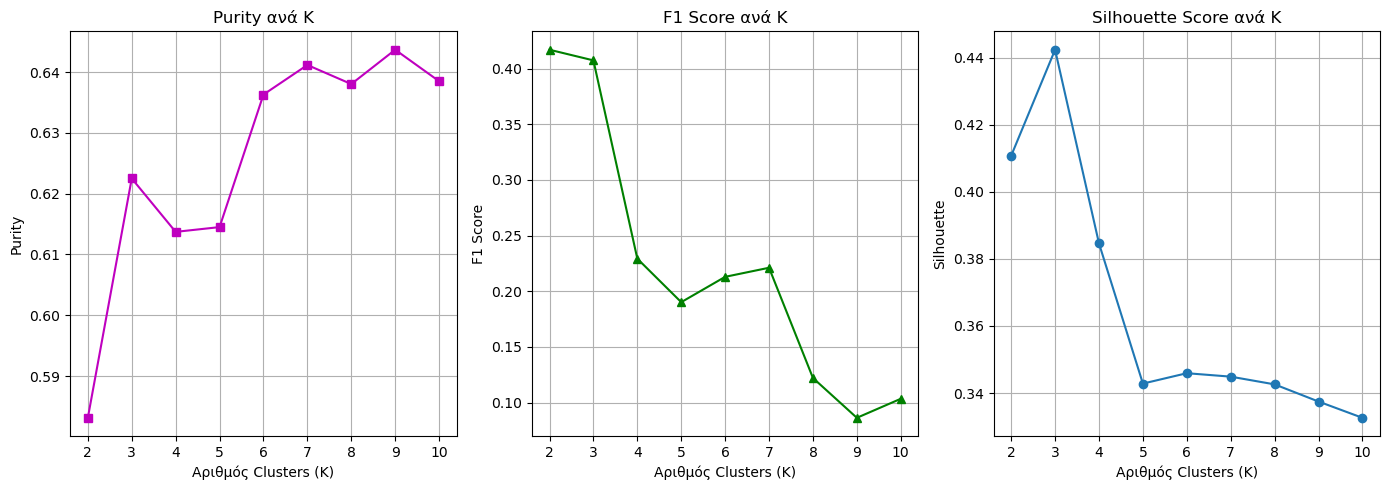


--- Agglomerative Clustering για M = 2 ---
Agglomerative | K = 2 | Purity = 0.5607 | F-measure = 0.5607 | Silhouette = 0.4067
Agglomerative | K = 3 | Purity = 0.5759 | F-measure = 0.4374 | Silhouette = 0.4154
Agglomerative | K = 4 | Purity = 0.6073 | F-measure = 0.3581 | Silhouette = 0.3167
Agglomerative | K = 5 | Purity = 0.6277 | F-measure = 0.2925 | Silhouette = 0.3280
Agglomerative | K = 6 | Purity = 0.6277 | F-measure = 0.2704 | Silhouette = 0.3215
Agglomerative | K = 7 | Purity = 0.6277 | F-measure = 0.2500 | Silhouette = 0.3221
Agglomerative | K = 8 | Purity = 0.6277 | F-measure = 0.1589 | Silhouette = 0.2990
Agglomerative | K = 9 | Purity = 0.6277 | F-measure = 0.0615 | Silhouette = 0.2752
Agglomerative | K = 10 | Purity = 0.6302 | F-measure = 0.1134 | Silhouette = 0.2752
Best k = 3 with Silhouette Score: 0.41537204


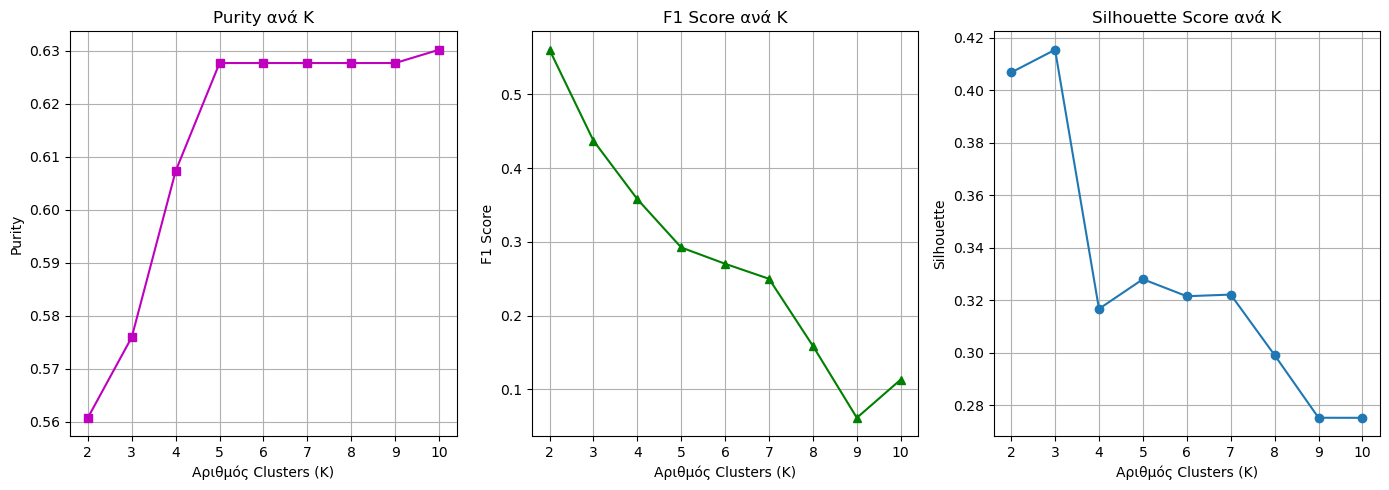


===== PCA + KMeans for M = 3 =====
KMeans (Cosine) | K = 2 | Purity = 0.5822 | F-measure = 0.4178 | Silhouette = 0.3458
KMeans (Cosine) | K = 3 | Purity = 0.6211 | F-measure = 0.3472 | Silhouette = 0.3597
KMeans (Cosine) | K = 4 | Purity = 0.6148 | F-measure = 0.2825 | Silhouette = 0.2936
KMeans (Cosine) | K = 5 | Purity = 0.6515 | F-measure = 0.1041 | Silhouette = 0.3098
KMeans (Cosine) | K = 6 | Purity = 0.6606 | F-measure = 0.1978 | Silhouette = 0.3005
KMeans (Cosine) | K = 7 | Purity = 0.6603 | F-measure = 0.1045 | Silhouette = 0.2628
KMeans (Cosine) | K = 8 | Purity = 0.6752 | F-measure = 0.2072 | Silhouette = 0.2602
KMeans (Cosine) | K = 9 | Purity = 0.6551 | F-measure = 0.0775 | Silhouette = 0.2496
KMeans (Cosine) | K = 10 | Purity = 0.6716 | F-measure = 0.1865 | Silhouette = 0.2533
Best k = 3 with Silhouette Score: 0.3597239


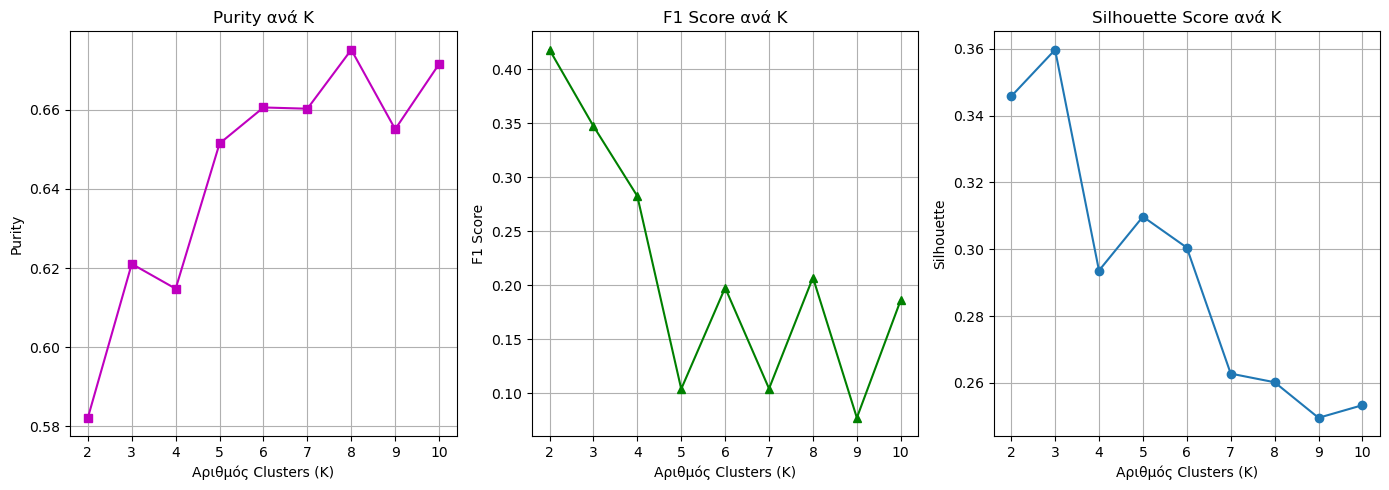


--- Agglomerative Clustering για M = 3 ---
Agglomerative | K = 2 | Purity = 0.5842 | F-measure = 0.5842 | Silhouette = 0.3133
Agglomerative | K = 3 | Purity = 0.6024 | F-measure = 0.4451 | Silhouette = 0.3317
Agglomerative | K = 4 | Purity = 0.6114 | F-measure = 0.3093 | Silhouette = 0.2382
Agglomerative | K = 5 | Purity = 0.6546 | F-measure = 0.2113 | Silhouette = 0.2061
Agglomerative | K = 6 | Purity = 0.6546 | F-measure = 0.2168 | Silhouette = 0.2122
Agglomerative | K = 7 | Purity = 0.6546 | F-measure = 0.1303 | Silhouette = 0.1887
Agglomerative | K = 8 | Purity = 0.6648 | F-measure = 0.0987 | Silhouette = 0.1925
Agglomerative | K = 9 | Purity = 0.6648 | F-measure = 0.1946 | Silhouette = 0.1921
Agglomerative | K = 10 | Purity = 0.6648 | F-measure = 0.1168 | Silhouette = 0.1979
Best k = 3 with Silhouette Score: 0.33170736


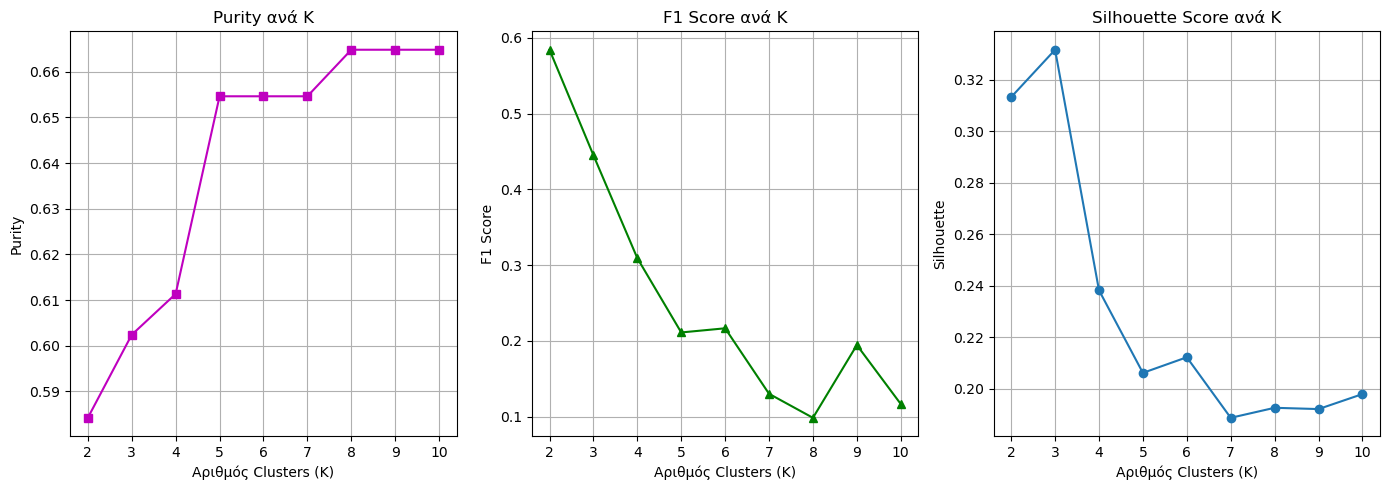


===== PCA + KMeans for M = 5 =====
KMeans (Cosine) | K = 2 | Purity = 0.5847 | F-measure = 0.5847 | Silhouette = 0.2866
KMeans (Cosine) | K = 3 | Purity = 0.6219 | F-measure = 0.4075 | Silhouette = 0.2898
KMeans (Cosine) | K = 4 | Purity = 0.6173 | F-measure = 0.2174 | Silhouette = 0.2216
KMeans (Cosine) | K = 5 | Purity = 0.6474 | F-measure = 0.1358 | Silhouette = 0.2141
KMeans (Cosine) | K = 6 | Purity = 0.6584 | F-measure = 0.1294 | Silhouette = 0.2247
KMeans (Cosine) | K = 7 | Purity = 0.6539 | F-measure = 0.1330 | Silhouette = 0.2174
KMeans (Cosine) | K = 8 | Purity = 0.6506 | F-measure = 0.1066 | Silhouette = 0.1905
KMeans (Cosine) | K = 9 | Purity = 0.6452 | F-measure = 0.0463 | Silhouette = 0.1848
KMeans (Cosine) | K = 10 | Purity = 0.6496 | F-measure = 0.0535 | Silhouette = 0.1829
Best k = 3 with Silhouette Score: 0.2897774


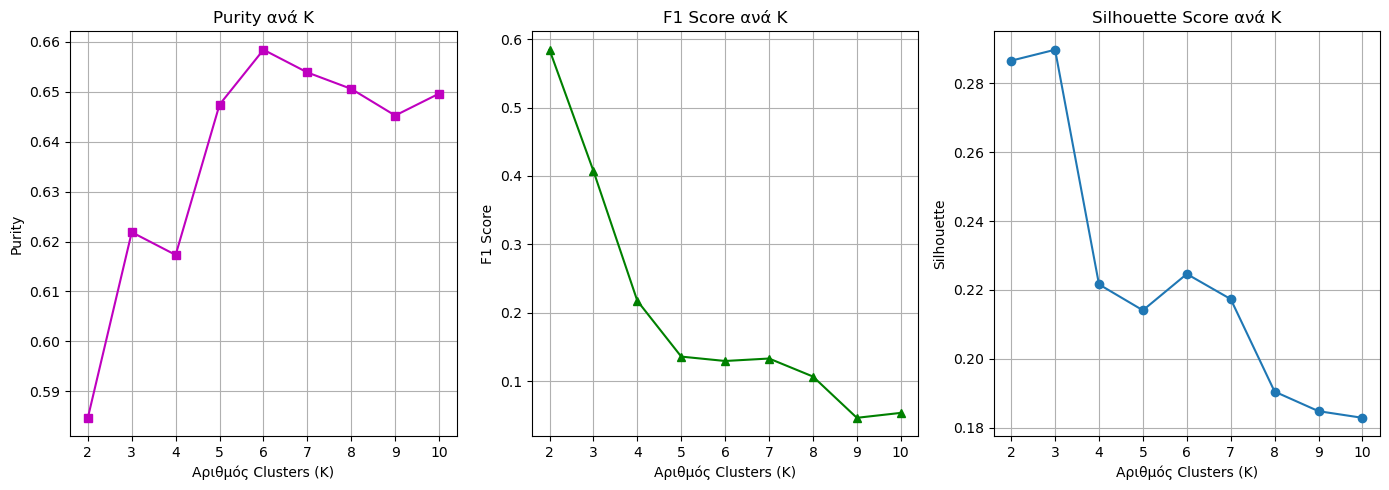


--- Agglomerative Clustering για M = 5 ---
Agglomerative | K = 2 | Purity = 0.6082 | F-measure = 0.6082 | Silhouette = 0.2177
Agglomerative | K = 3 | Purity = 0.6134 | F-measure = 0.4566 | Silhouette = 0.2457
Agglomerative | K = 4 | Purity = 0.6503 | F-measure = 0.3949 | Silhouette = 0.2406
Agglomerative | K = 5 | Purity = 0.6503 | F-measure = 0.4046 | Silhouette = 0.1853
Agglomerative | K = 6 | Purity = 0.6503 | F-measure = 0.2801 | Silhouette = 0.1868
Agglomerative | K = 7 | Purity = 0.6503 | F-measure = 0.1699 | Silhouette = 0.1181
Agglomerative | K = 8 | Purity = 0.6503 | F-measure = 0.0805 | Silhouette = 0.1219
Agglomerative | K = 9 | Purity = 0.6506 | F-measure = 0.1114 | Silhouette = 0.1092
Agglomerative | K = 10 | Purity = 0.6529 | F-measure = 0.1427 | Silhouette = 0.1114
Best k = 3 with Silhouette Score: 0.24567665


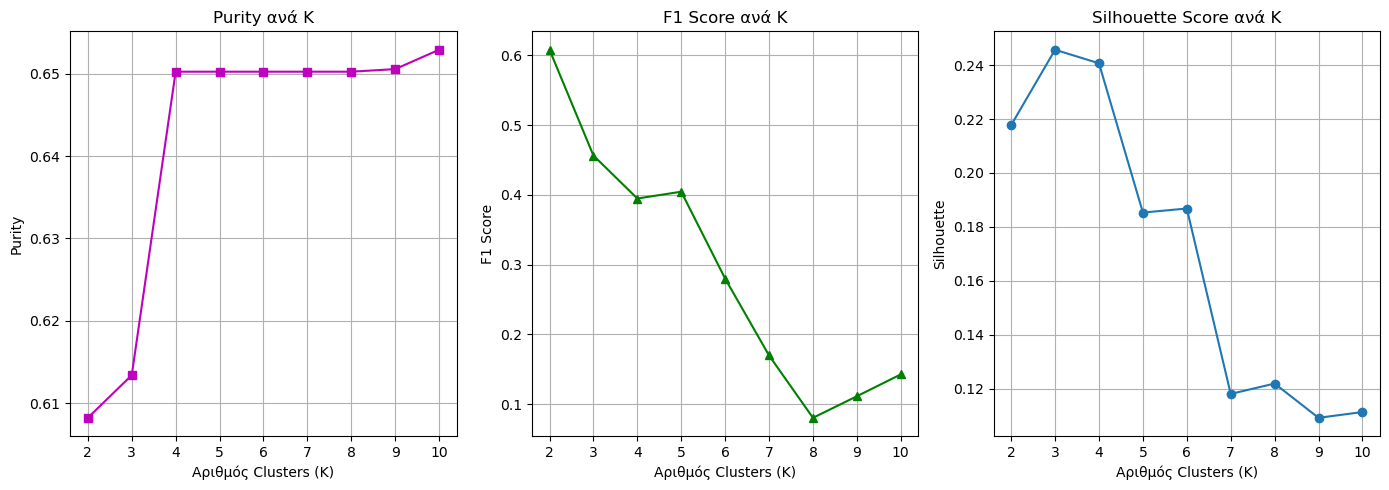


===== PCA + KMeans for M = 10 =====
KMeans (Cosine) | K = 2 | Purity = 0.5838 | F-measure = 0.5838 | Silhouette = 0.2463
KMeans (Cosine) | K = 3 | Purity = 0.6192 | F-measure = 0.4087 | Silhouette = 0.2447
KMeans (Cosine) | K = 4 | Purity = 0.6154 | F-measure = 0.0789 | Silhouette = 0.1777
KMeans (Cosine) | K = 5 | Purity = 0.6492 | F-measure = 0.2050 | Silhouette = 0.1830
KMeans (Cosine) | K = 6 | Purity = 0.6592 | F-measure = 0.0703 | Silhouette = 0.1777
KMeans (Cosine) | K = 7 | Purity = 0.6510 | F-measure = 0.1614 | Silhouette = 0.1764
KMeans (Cosine) | K = 8 | Purity = 0.6328 | F-measure = 0.2285 | Silhouette = 0.1364
KMeans (Cosine) | K = 9 | Purity = 0.6471 | F-measure = 0.2034 | Silhouette = 0.1378
KMeans (Cosine) | K = 10 | Purity = 0.6444 | F-measure = 0.1037 | Silhouette = 0.1361
Best k = 2 with Silhouette Score: 0.24627422


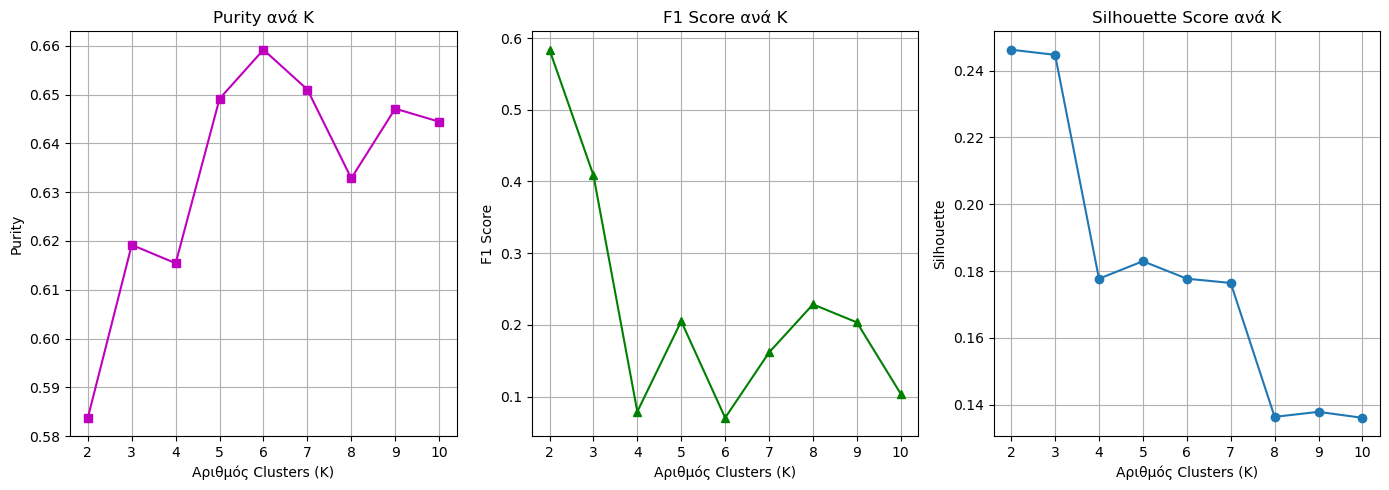


--- Agglomerative Clustering για M = 10 ---
Agglomerative | K = 2 | Purity = 0.6137 | F-measure = 0.6137 | Silhouette = 0.1792
Agglomerative | K = 3 | Purity = 0.6137 | F-measure = 0.4738 | Silhouette = 0.2005
Agglomerative | K = 4 | Purity = 0.6137 | F-measure = 0.4082 | Silhouette = 0.1636
Agglomerative | K = 5 | Purity = 0.6325 | F-measure = 0.3988 | Silhouette = 0.1586
Agglomerative | K = 6 | Purity = 0.6325 | F-measure = 0.2378 | Silhouette = 0.1577
Agglomerative | K = 7 | Purity = 0.6325 | F-measure = 0.1741 | Silhouette = 0.0930
Agglomerative | K = 8 | Purity = 0.6325 | F-measure = 0.1879 | Silhouette = 0.0692
Agglomerative | K = 9 | Purity = 0.6325 | F-measure = 0.2348 | Silhouette = 0.0701
Agglomerative | K = 10 | Purity = 0.6325 | F-measure = 0.1851 | Silhouette = 0.0674
Best k = 3 with Silhouette Score: 0.20053633


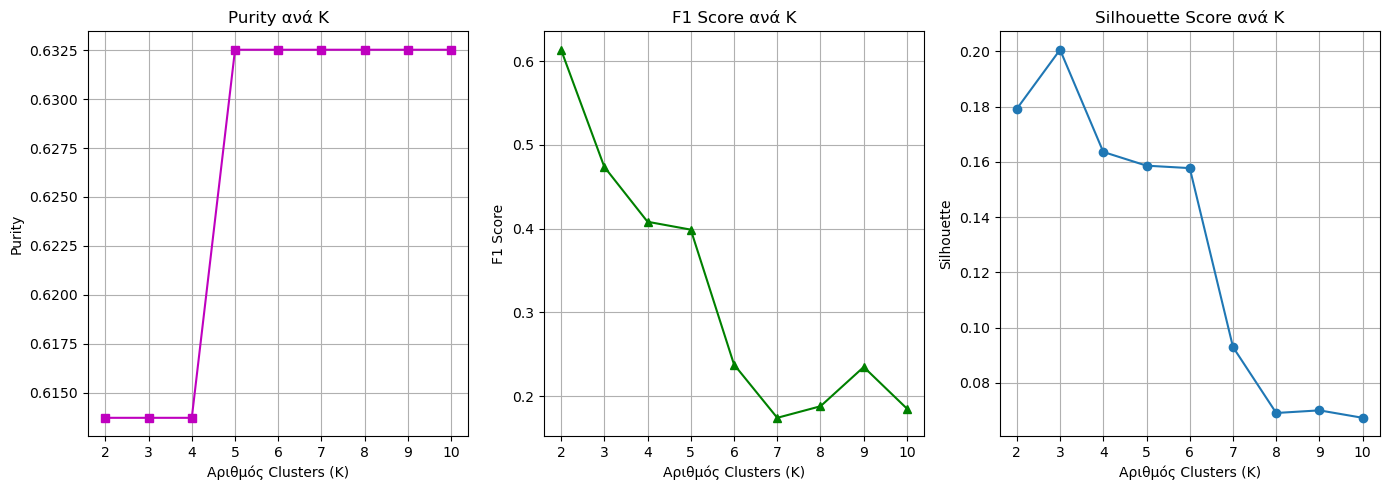


===== PCA + KMeans for M = 20 =====
KMeans (Cosine) | K = 2 | Purity = 0.5842 | F-measure = 0.4158 | Silhouette = 0.2268
KMeans (Cosine) | K = 3 | Purity = 0.6201 | F-measure = 0.3450 | Silhouette = 0.2226
KMeans (Cosine) | K = 4 | Purity = 0.6550 | F-measure = 0.4095 | Silhouette = 0.2137
KMeans (Cosine) | K = 5 | Purity = 0.6488 | F-measure = 0.2527 | Silhouette = 0.1614
KMeans (Cosine) | K = 6 | Purity = 0.6397 | F-measure = 0.1829 | Silhouette = 0.1472
KMeans (Cosine) | K = 7 | Purity = 0.6510 | F-measure = 0.1190 | Silhouette = 0.1549
KMeans (Cosine) | K = 8 | Purity = 0.6474 | F-measure = 0.1426 | Silhouette = 0.1372
KMeans (Cosine) | K = 9 | Purity = 0.6466 | F-measure = 0.1887 | Silhouette = 0.1176
KMeans (Cosine) | K = 10 | Purity = 0.6546 | F-measure = 0.0743 | Silhouette = 0.1122
Best k = 2 with Silhouette Score: 0.22683583


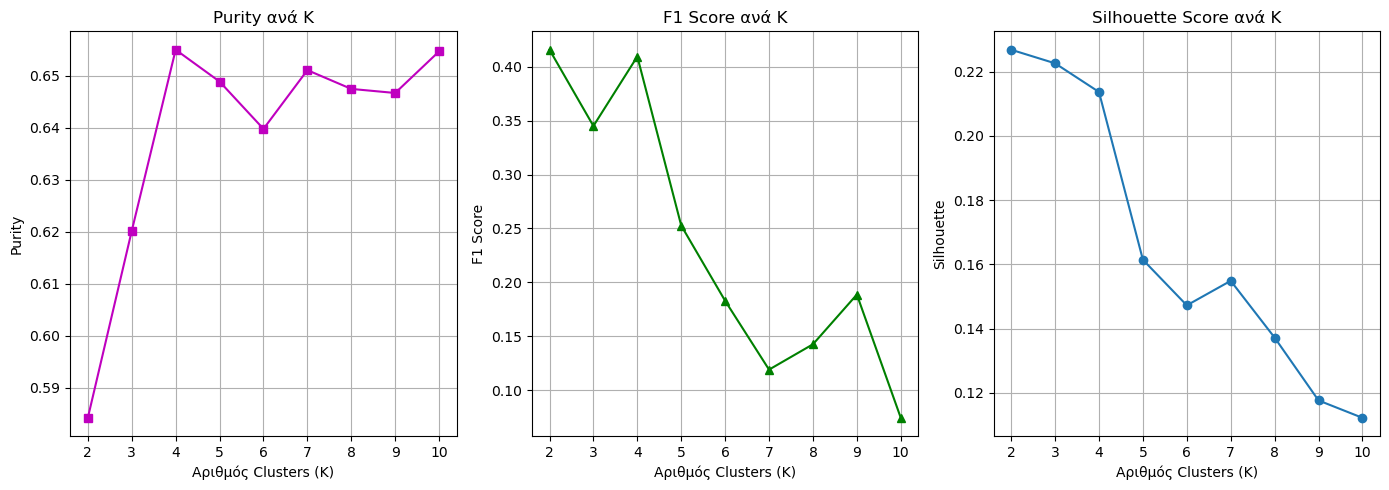


--- Agglomerative Clustering για M = 20 ---
Agglomerative | K = 2 | Purity = 0.6134 | F-measure = 0.6134 | Silhouette = 0.2136
Agglomerative | K = 3 | Purity = 0.6146 | F-measure = 0.2727 | Silhouette = 0.2249
Agglomerative | K = 4 | Purity = 0.6146 | F-measure = 0.3413 | Silhouette = 0.1081
Agglomerative | K = 5 | Purity = 0.6146 | F-measure = 0.3027 | Silhouette = 0.1046
Agglomerative | K = 6 | Purity = 0.6259 | F-measure = 0.2721 | Silhouette = 0.0934
Agglomerative | K = 7 | Purity = 0.6322 | F-measure = 0.2061 | Silhouette = 0.0962
Agglomerative | K = 8 | Purity = 0.6322 | F-measure = 0.1468 | Silhouette = 0.0807
Agglomerative | K = 9 | Purity = 0.6430 | F-measure = 0.1570 | Silhouette = 0.0863
Agglomerative | K = 10 | Purity = 0.6430 | F-measure = 0.0930 | Silhouette = 0.0602
Best k = 3 with Silhouette Score: 0.22492696


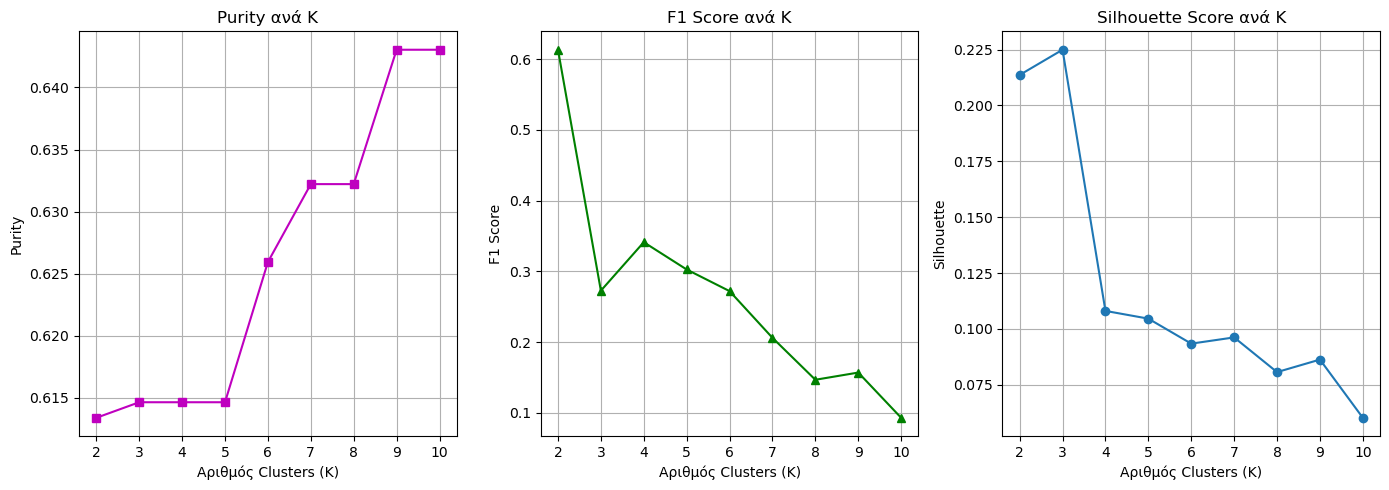

In [20]:
#PCA gia M=2,3,5,10,20

M_values= [2,3,5,10,20]

for M in M_values:
    print(f"\n===== PCA + KMeans for M = {M} =====")

    #PCA
    pca = PCA(n_components=M)
    x_reduced= pca.fit_transform(x)

    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    best_k = None

    for k in range(2,11):

        #Ευκλίδεια Απόσταση
        kmeans_model= KMeans(n_clusters=k, n_init="auto")
        kmeans_model.fit(x_reduced)
        labels= kmeans_model.labels_

        #υπολογισμος Purity
        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)

        #υπολογισμος F-measure
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        #υπολογισμος Silhoutte
        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            best_k = k
            
        print(f"KMeans (Cosine) | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


    #Agglomerative Clustering
    print(f"\n--- Agglomerative Clustering για M = {M} ---")
    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    agg_best_k = None

    for k in range(2,11):
        
        agg = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward")
        labels = agg.fit_predict(x_reduced) 

        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)
        
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            agg_best_k = k

        print(f"Agglomerative | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", agg_best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()




===== LLE + KMeans for M = 2 =====
KMeans (Cosine) | K = 2 | Purity = 0.6179 | F-measure = 0.3821 | Silhouette = 0.6557
KMeans (Cosine) | K = 3 | Purity = 0.6513 | F-measure = 0.3463 | Silhouette = 0.7127
KMeans (Cosine) | K = 4 | Purity = 0.6521 | F-measure = 0.3425 | Silhouette = 0.5478
KMeans (Cosine) | K = 5 | Purity = 0.6506 | F-measure = 0.2376 | Silhouette = 0.5221
KMeans (Cosine) | K = 6 | Purity = 0.6521 | F-measure = 0.0380 | Silhouette = 0.4944
KMeans (Cosine) | K = 7 | Purity = 0.6504 | F-measure = 0.1586 | Silhouette = 0.4759
KMeans (Cosine) | K = 8 | Purity = 0.6495 | F-measure = 0.1013 | Silhouette = 0.4642
KMeans (Cosine) | K = 9 | Purity = 0.6523 | F-measure = 0.3022 | Silhouette = 0.4624
KMeans (Cosine) | K = 10 | Purity = 0.6526 | F-measure = 0.2931 | Silhouette = 0.4667
Best k = 3 with Silhouette Score: 0.7126825413587097


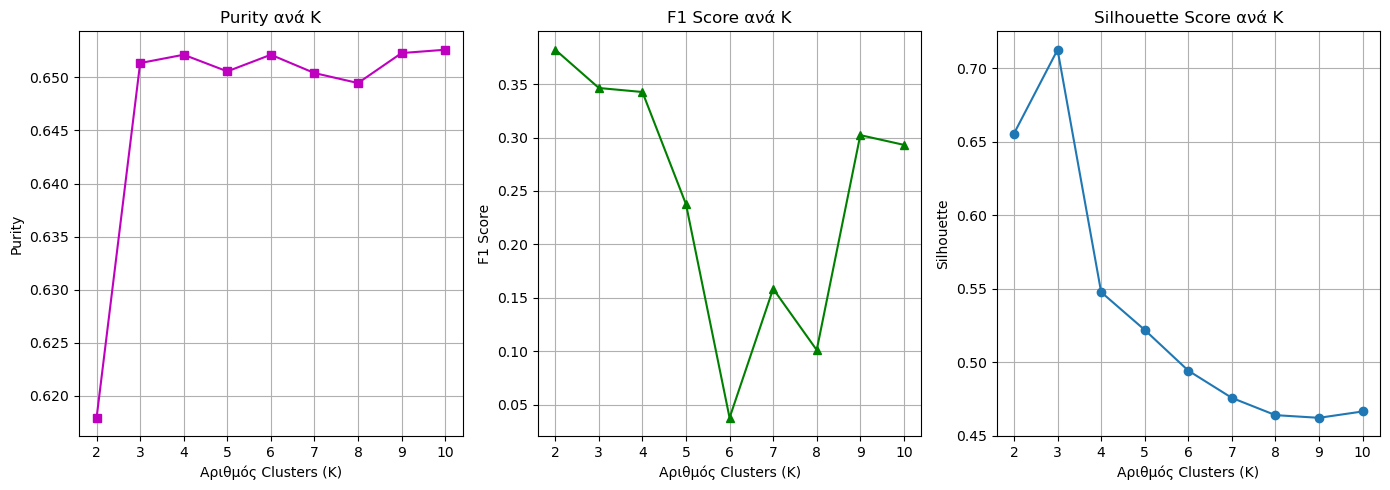


--- Agglomerative Clustering για M = 2 ---
Agglomerative | K = 2 | Purity = 0.6203 | F-measure = 0.3797 | Silhouette = 0.6532
Agglomerative | K = 3 | Purity = 0.6465 | F-measure = 0.3501 | Silhouette = 0.6987
Agglomerative | K = 4 | Purity = 0.6561 | F-measure = 0.0325 | Silhouette = 0.5474
Agglomerative | K = 5 | Purity = 0.6561 | F-measure = 0.2428 | Silhouette = 0.5478
Agglomerative | K = 6 | Purity = 0.6561 | F-measure = 0.3377 | Silhouette = 0.5323
Agglomerative | K = 7 | Purity = 0.6561 | F-measure = 0.3474 | Silhouette = 0.4539
Agglomerative | K = 8 | Purity = 0.6561 | F-measure = 0.3380 | Silhouette = 0.4575
Agglomerative | K = 9 | Purity = 0.6561 | F-measure = 0.1815 | Silhouette = 0.4305
Agglomerative | K = 10 | Purity = 0.6561 | F-measure = 0.0056 | Silhouette = 0.3868
Best k = 3 with Silhouette Score: 0.698705628280433


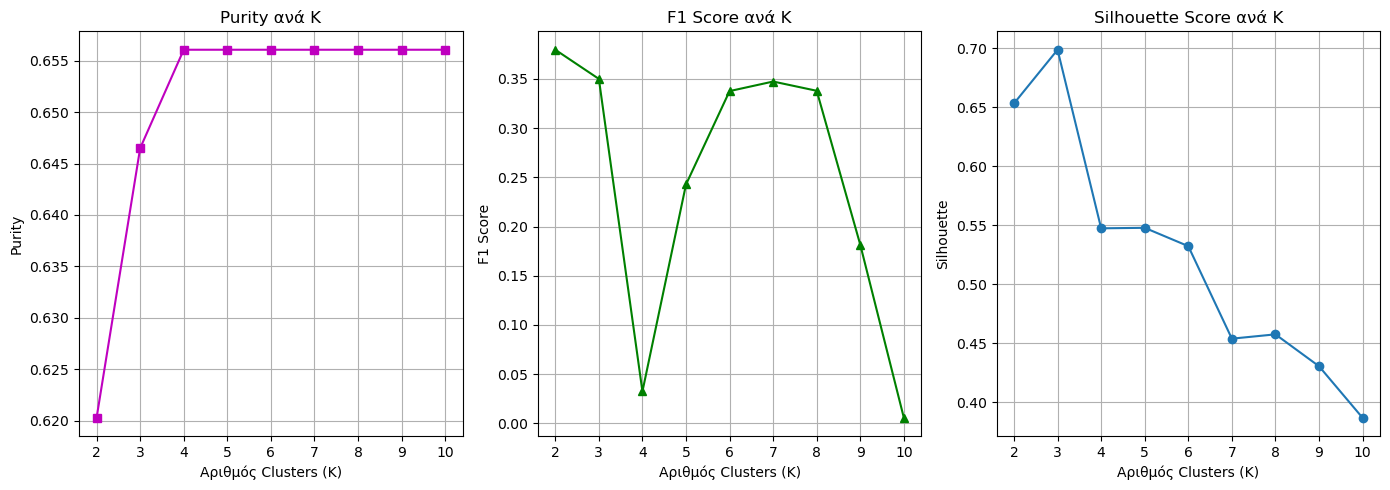


===== LLE + KMeans for M = 3 =====
KMeans (Cosine) | K = 2 | Purity = 0.5323 | F-measure = 0.5318 | Silhouette = 0.9207
KMeans (Cosine) | K = 3 | Purity = 0.6504 | F-measure = 0.4978 | Silhouette = 0.6129
KMeans (Cosine) | K = 4 | Purity = 0.6457 | F-measure = 0.2163 | Silhouette = 0.4481
KMeans (Cosine) | K = 5 | Purity = 0.6457 | F-measure = 0.3731 | Silhouette = 0.4426
KMeans (Cosine) | K = 6 | Purity = 0.6452 | F-measure = 0.3361 | Silhouette = 0.4217
KMeans (Cosine) | K = 7 | Purity = 0.6479 | F-measure = 0.3424 | Silhouette = 0.4354
KMeans (Cosine) | K = 8 | Purity = 0.6470 | F-measure = 0.1115 | Silhouette = 0.4289
KMeans (Cosine) | K = 9 | Purity = 0.6542 | F-measure = 0.1838 | Silhouette = 0.4092
KMeans (Cosine) | K = 10 | Purity = 0.6454 | F-measure = 0.1183 | Silhouette = 0.4148
Best k = 2 with Silhouette Score: 0.9206700165016056


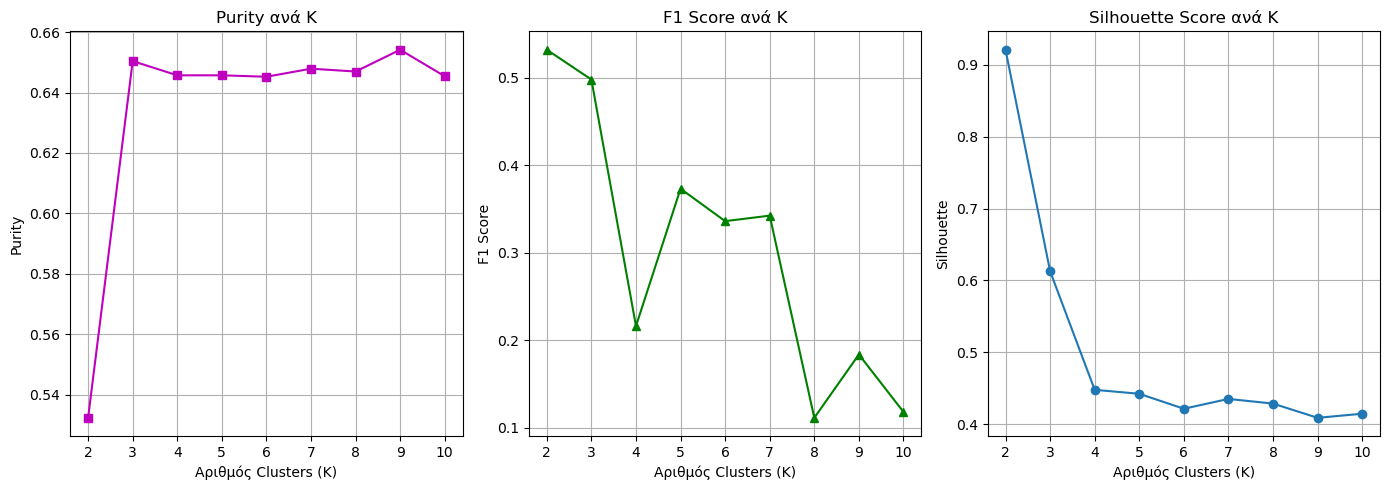


--- Agglomerative Clustering για M = 3 ---
Agglomerative | K = 2 | Purity = 0.6192 | F-measure = 0.3808 | Silhouette = 0.5411
Agglomerative | K = 3 | Purity = 0.6553 | F-measure = 0.3225 | Silhouette = 0.5924
Agglomerative | K = 4 | Purity = 0.6557 | F-measure = 0.3220 | Silhouette = 0.5969
Agglomerative | K = 5 | Purity = 0.6557 | F-measure = 0.3626 | Silhouette = 0.4254
Agglomerative | K = 6 | Purity = 0.6557 | F-measure = 0.4021 | Silhouette = 0.4329
Agglomerative | K = 7 | Purity = 0.6557 | F-measure = 0.2241 | Silhouette = 0.4053
Agglomerative | K = 8 | Purity = 0.6557 | F-measure = 0.1681 | Silhouette = 0.3694
Agglomerative | K = 9 | Purity = 0.6557 | F-measure = 0.0347 | Silhouette = 0.3521
Agglomerative | K = 10 | Purity = 0.6557 | F-measure = 0.1876 | Silhouette = 0.3525
Best k = 4 with Silhouette Score: 0.5968518403283188


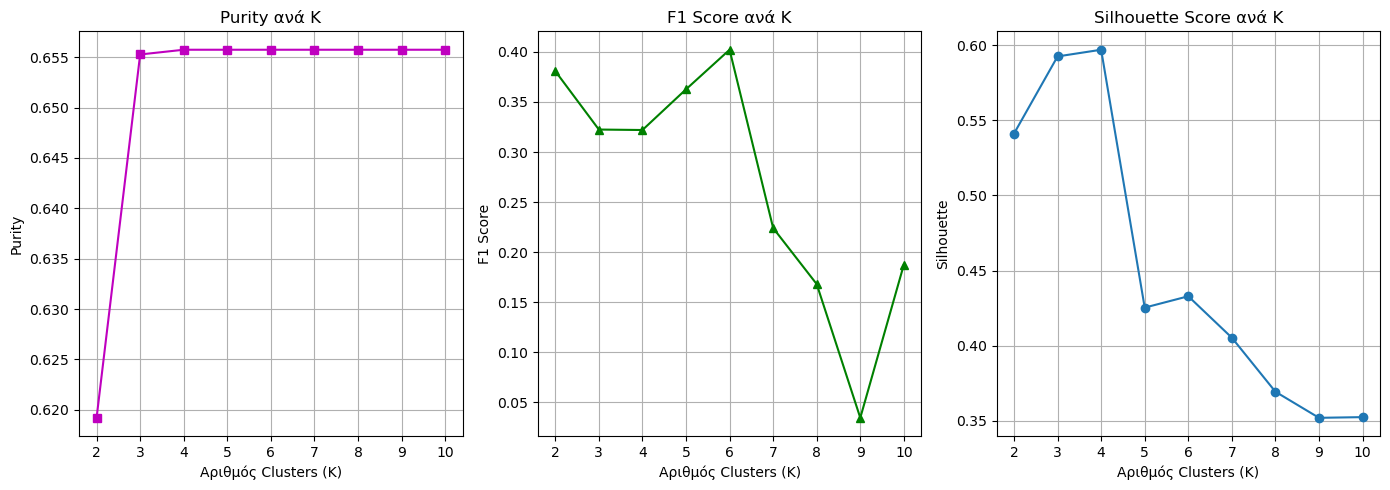


===== LLE + KMeans for M = 5 =====
KMeans (Cosine) | K = 2 | Purity = 0.6212 | F-measure = 0.3788 | Silhouette = 0.4534
KMeans (Cosine) | K = 3 | Purity = 0.6200 | F-measure = 0.3988 | Silhouette = 0.4148
KMeans (Cosine) | K = 4 | Purity = 0.6515 | F-measure = 0.4012 | Silhouette = 0.4342
KMeans (Cosine) | K = 5 | Purity = 0.6518 | F-measure = 0.2643 | Silhouette = 0.4401
KMeans (Cosine) | K = 6 | Purity = 0.6482 | F-measure = 0.3359 | Silhouette = 0.3593
KMeans (Cosine) | K = 7 | Purity = 0.6492 | F-measure = 0.2779 | Silhouette = 0.4812
KMeans (Cosine) | K = 8 | Purity = 0.6487 | F-measure = 0.1987 | Silhouette = 0.3789
KMeans (Cosine) | K = 9 | Purity = 0.6528 | F-measure = 0.1286 | Silhouette = 0.3783
KMeans (Cosine) | K = 10 | Purity = 0.6490 | F-measure = 0.2301 | Silhouette = 0.3813
Best k = 7 with Silhouette Score: 0.4811911509397406


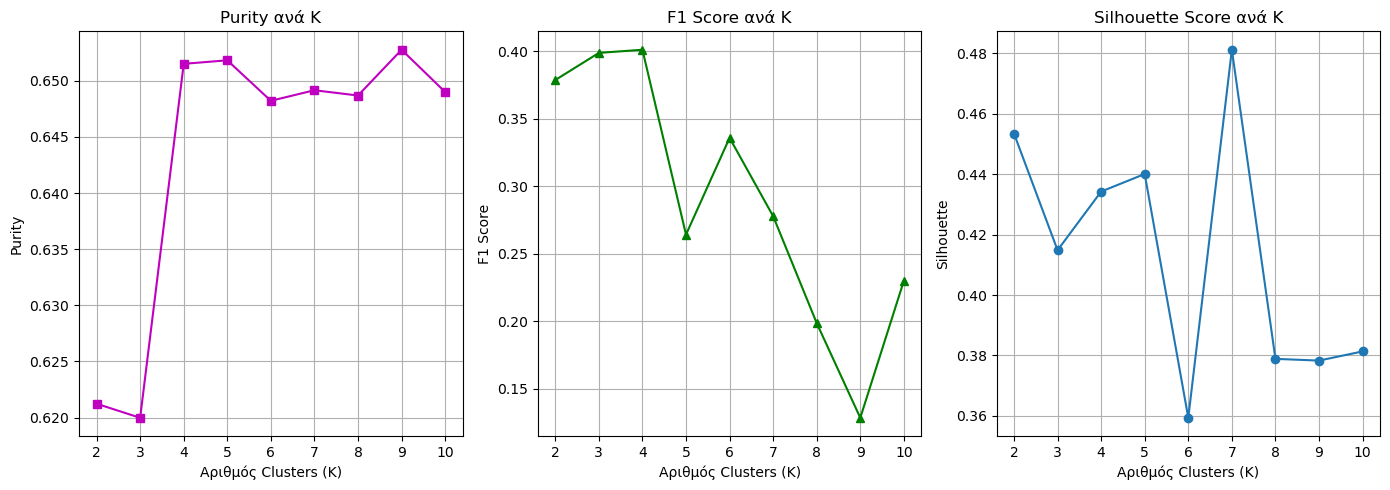


--- Agglomerative Clustering για M = 5 ---
Agglomerative | K = 2 | Purity = 0.6126 | F-measure = 0.3874 | Silhouette = 0.4527
Agglomerative | K = 3 | Purity = 0.6126 | F-measure = 0.0797 | Silhouette = 0.3597
Agglomerative | K = 4 | Purity = 0.6131 | F-measure = 0.3098 | Silhouette = 0.3526
Agglomerative | K = 5 | Purity = 0.6397 | F-measure = 0.1854 | Silhouette = 0.4156
Agglomerative | K = 6 | Purity = 0.6397 | F-measure = 0.3675 | Silhouette = 0.4442
Agglomerative | K = 7 | Purity = 0.6397 | F-measure = 0.2811 | Silhouette = 0.4533
Agglomerative | K = 8 | Purity = 0.6397 | F-measure = 0.0621 | Silhouette = 0.4607
Agglomerative | K = 9 | Purity = 0.6446 | F-measure = 0.0789 | Silhouette = 0.4523
Agglomerative | K = 10 | Purity = 0.6446 | F-measure = 0.1065 | Silhouette = 0.4178
Best k = 8 with Silhouette Score: 0.46074403542830294


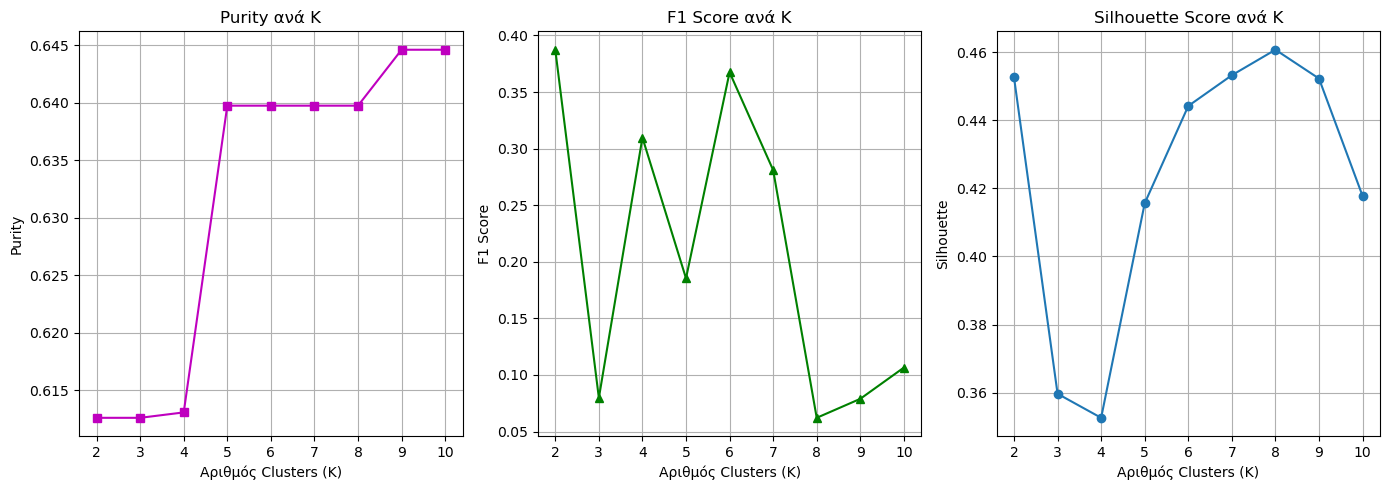


===== LLE + KMeans for M = 10 =====
KMeans (Cosine) | K = 2 | Purity = 0.6195 | F-measure = 0.6195 | Silhouette = 0.3812
KMeans (Cosine) | K = 3 | Purity = 0.5885 | F-measure = 0.5880 | Silhouette = 0.1514
KMeans (Cosine) | K = 4 | Purity = 0.6523 | F-measure = 0.0590 | Silhouette = 0.2708
KMeans (Cosine) | K = 5 | Purity = 0.6463 | F-measure = 0.0729 | Silhouette = 0.2443
KMeans (Cosine) | K = 6 | Purity = 0.6484 | F-measure = 0.1159 | Silhouette = 0.3172
KMeans (Cosine) | K = 7 | Purity = 0.6465 | F-measure = 0.2875 | Silhouette = 0.3098
KMeans (Cosine) | K = 8 | Purity = 0.6435 | F-measure = 0.4112 | Silhouette = 0.3410
KMeans (Cosine) | K = 9 | Purity = 0.6441 | F-measure = 0.4657 | Silhouette = 0.3232
KMeans (Cosine) | K = 10 | Purity = 0.6440 | F-measure = 0.0828 | Silhouette = 0.2541
Best k = 2 with Silhouette Score: 0.38117183455972675


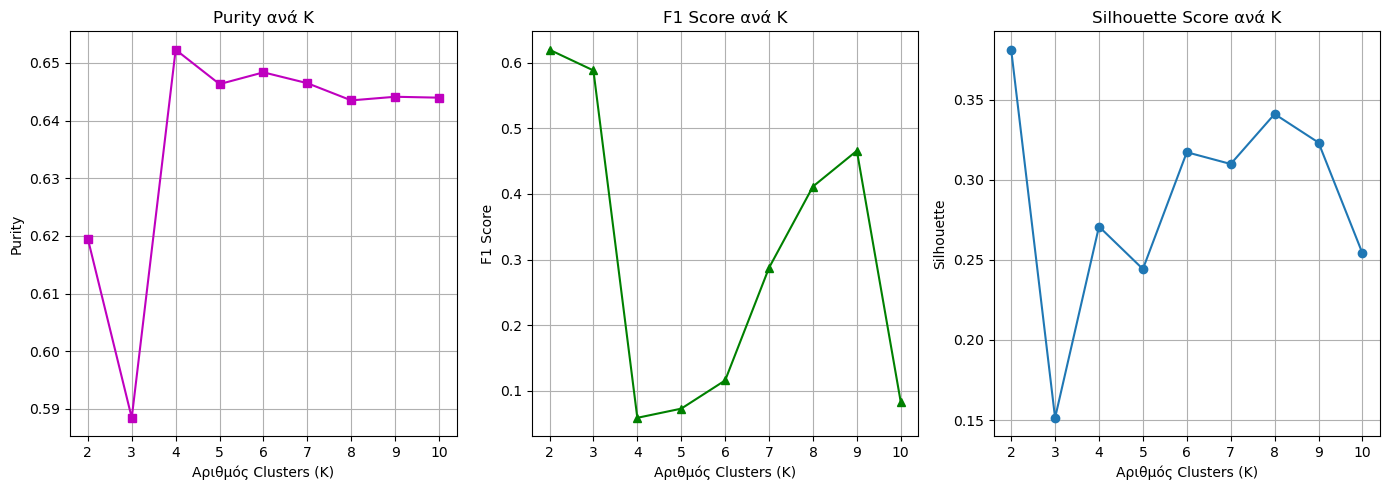


--- Agglomerative Clustering για M = 10 ---
Agglomerative | K = 2 | Purity = 0.6184 | F-measure = 0.3816 | Silhouette = 0.3524
Agglomerative | K = 3 | Purity = 0.6236 | F-measure = 0.3764 | Silhouette = 0.3635
Agglomerative | K = 4 | Purity = 0.6236 | F-measure = 0.4199 | Silhouette = 0.2674
Agglomerative | K = 5 | Purity = 0.6241 | F-measure = 0.3356 | Silhouette = 0.2534
Agglomerative | K = 6 | Purity = 0.6419 | F-measure = 0.2393 | Silhouette = 0.2843
Agglomerative | K = 7 | Purity = 0.6419 | F-measure = 0.2177 | Silhouette = 0.3035
Agglomerative | K = 8 | Purity = 0.6419 | F-measure = 0.2171 | Silhouette = 0.3076
Agglomerative | K = 9 | Purity = 0.6419 | F-measure = 0.0875 | Silhouette = 0.3218
Agglomerative | K = 10 | Purity = 0.6426 | F-measure = 0.0750 | Silhouette = 0.3138
Best k = 3 with Silhouette Score: 0.3634986800778373


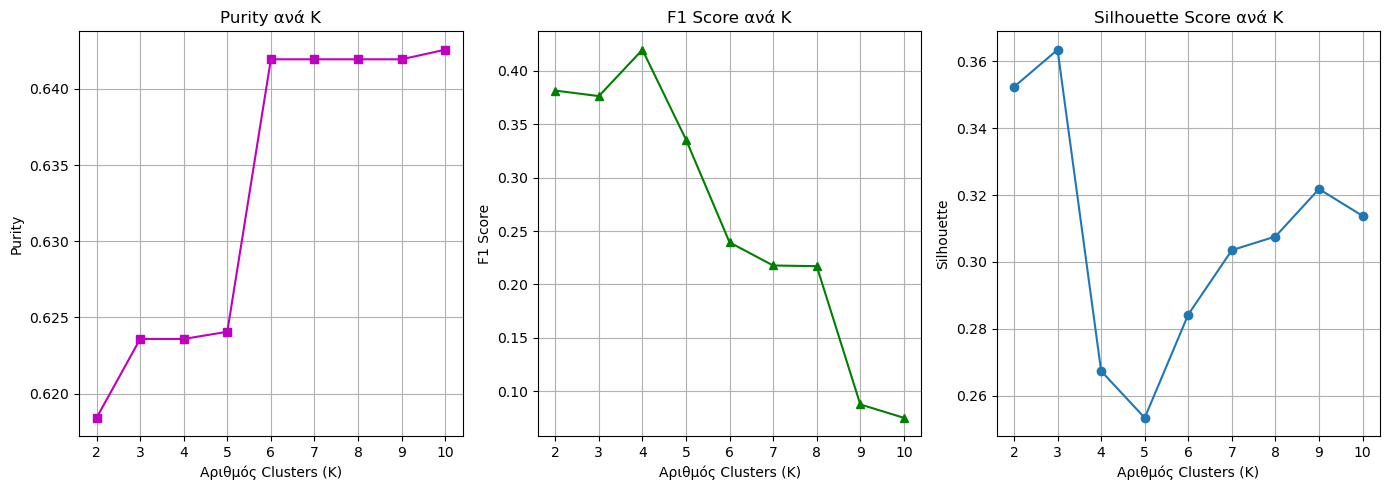


===== LLE + KMeans for M = 20 =====
KMeans (Cosine) | K = 2 | Purity = 0.5690 | F-measure = 0.5690 | Silhouette = 0.0567
KMeans (Cosine) | K = 3 | Purity = 0.6154 | F-measure = 0.4815 | Silhouette = 0.0837
KMeans (Cosine) | K = 4 | Purity = 0.6462 | F-measure = 0.0946 | Silhouette = 0.2548
KMeans (Cosine) | K = 5 | Purity = 0.6131 | F-measure = 0.2048 | Silhouette = 0.2211
KMeans (Cosine) | K = 6 | Purity = 0.6448 | F-measure = 0.0952 | Silhouette = 0.1766
KMeans (Cosine) | K = 7 | Purity = 0.6255 | F-measure = 0.2674 | Silhouette = 0.0892
KMeans (Cosine) | K = 8 | Purity = 0.6485 | F-measure = 0.3165 | Silhouette = 0.0859
KMeans (Cosine) | K = 9 | Purity = 0.6498 | F-measure = 0.1832 | Silhouette = 0.1235
KMeans (Cosine) | K = 10 | Purity = 0.6288 | F-measure = 0.1283 | Silhouette = 0.1287
Best k = 4 with Silhouette Score: 0.25477918538541505


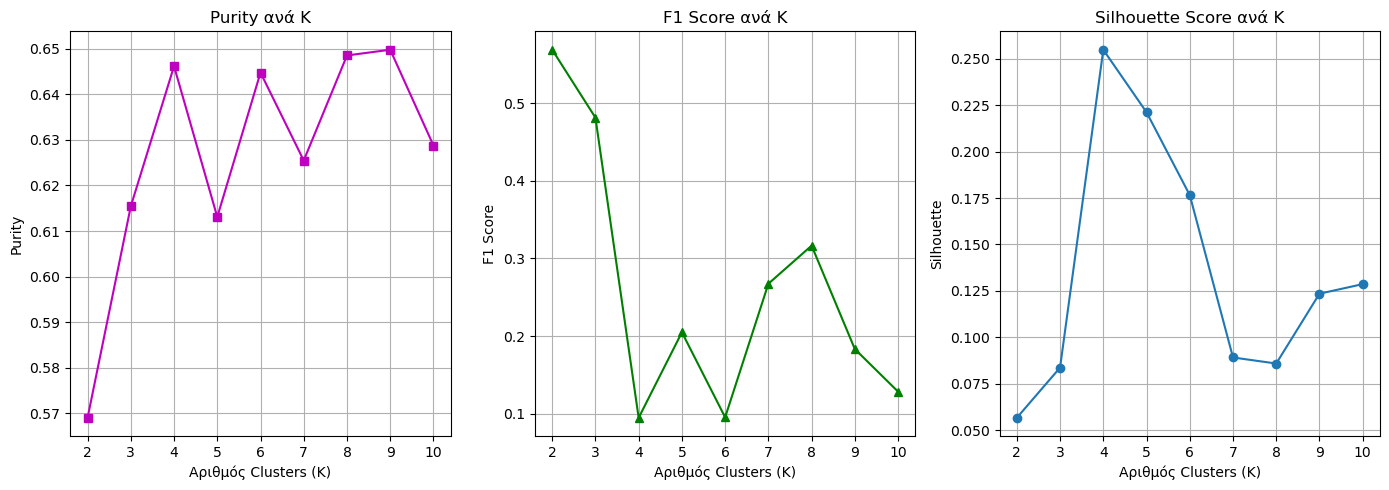


--- Agglomerative Clustering για M = 20 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


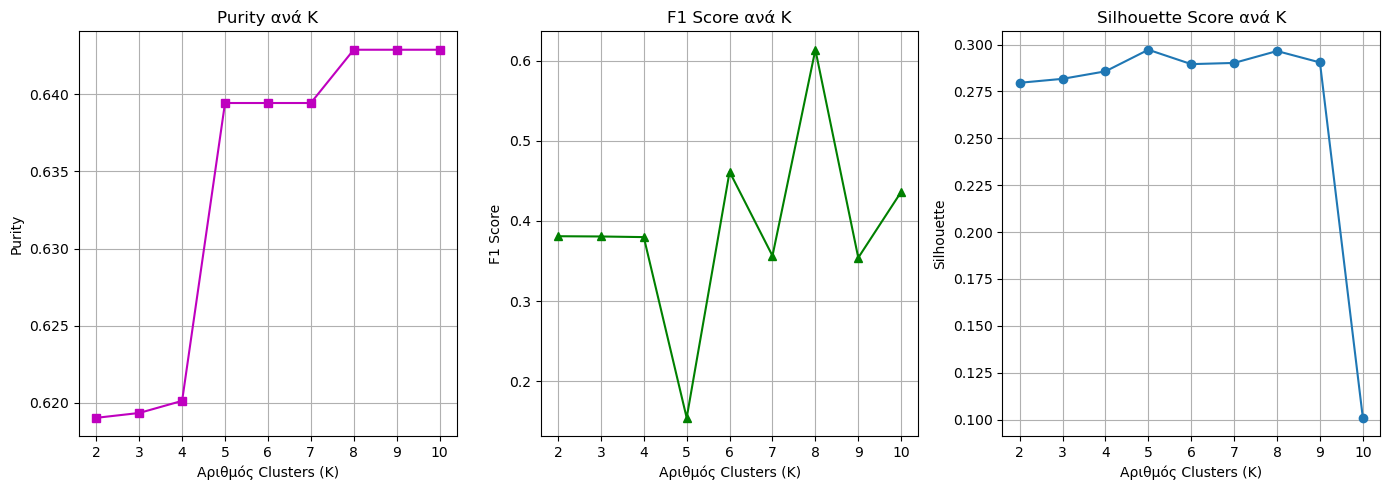

In [31]:
#LLE gia M=2,3,5,10,20

M_values= [2,3,5,10,20]

for M in M_values:
    print(f"\n===== LLE + KMeans for M = {M} =====")

    #LLE
    lle = LocallyLinearEmbedding(n_components=M, n_neighbors=12) # δημιουργούμε LLE με Μ=2 συνιστώσες 
    x_reduced = lle.fit_transform(x)

    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    best_k = None

    for k in range(2,11):

        #Ευκλίδεια Απόσταση
        kmeans_model= KMeans(n_clusters=k, n_init="auto")
        kmeans_model.fit(x_reduced)
        labels= kmeans_model.labels_

        #υπολογισμος Purity
        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)

        #υπολογισμος F-measure
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        #υπολογισμος Silhoutte
        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            best_k = k

        print(f"KMeans (Cosine) | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


    #Agglomerative Clustering
    print(f"\n--- Agglomerative Clustering για M = {M} ---")
    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    agg_best_k = None

    for k in range(2,11):
        
        agg = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward")
        labels = agg.fit_predict(x_reduced) 

        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)
        
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            agg_best_k = k

        print(f"Agglomerative | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", agg_best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()



===== Autoencoders + KMeans for M = 2 =====
KMeans (Cosine) | K = 2 | Purity = 0.5323 | F-measure = 0.5058 | Silhouette = 0.3984
KMeans (Cosine) | K = 3 | Purity = 0.5323 | F-measure = 0.5050 | Silhouette = 0.4458
KMeans (Cosine) | K = 4 | Purity = 0.5872 | F-measure = 0.3620 | Silhouette = 0.0700
KMeans (Cosine) | K = 5 | Purity = 0.6455 | F-measure = 0.3141 | Silhouette = 0.1058
KMeans (Cosine) | K = 6 | Purity = 0.5794 | F-measure = 0.1548 | Silhouette = 0.1054
KMeans (Cosine) | K = 7 | Purity = 0.6523 | F-measure = 0.2050 | Silhouette = 0.1153
KMeans (Cosine) | K = 8 | Purity = 0.6335 | F-measure = 0.0668 | Silhouette = 0.0846
KMeans (Cosine) | K = 9 | Purity = 0.6512 | F-measure = 0.1793 | Silhouette = 0.1348
KMeans (Cosine) | K = 10 | Purity = 0.6247 | F-measure = 0.0828 | Silhouette = 0.0981
Best k = 3 with Silhouette Score: 0.44582242308076475


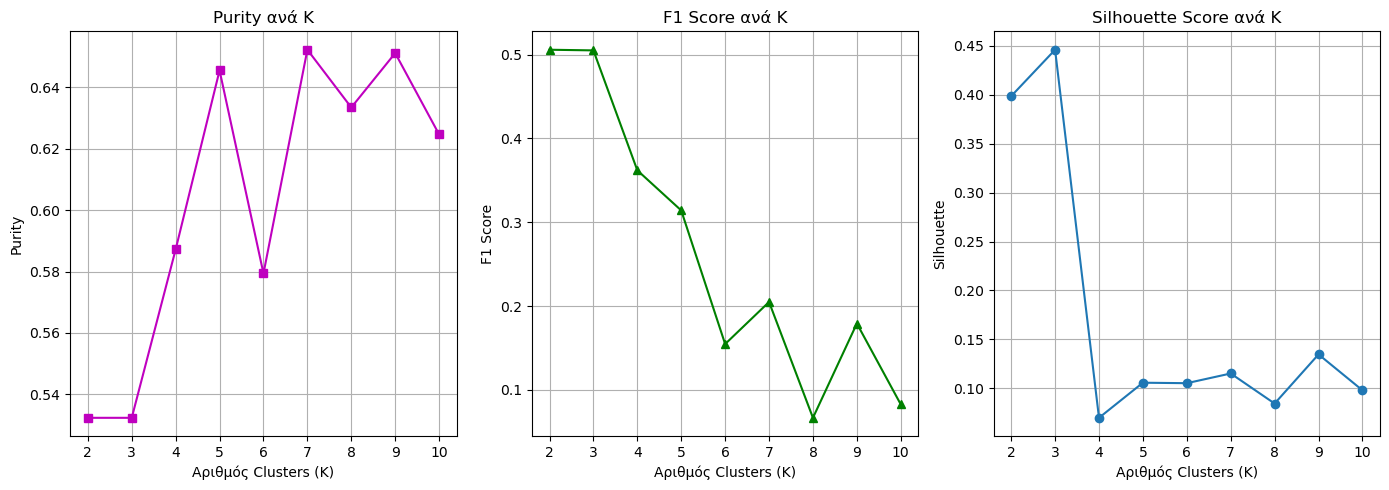


--- Agglomerative Clustering για M = 2 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


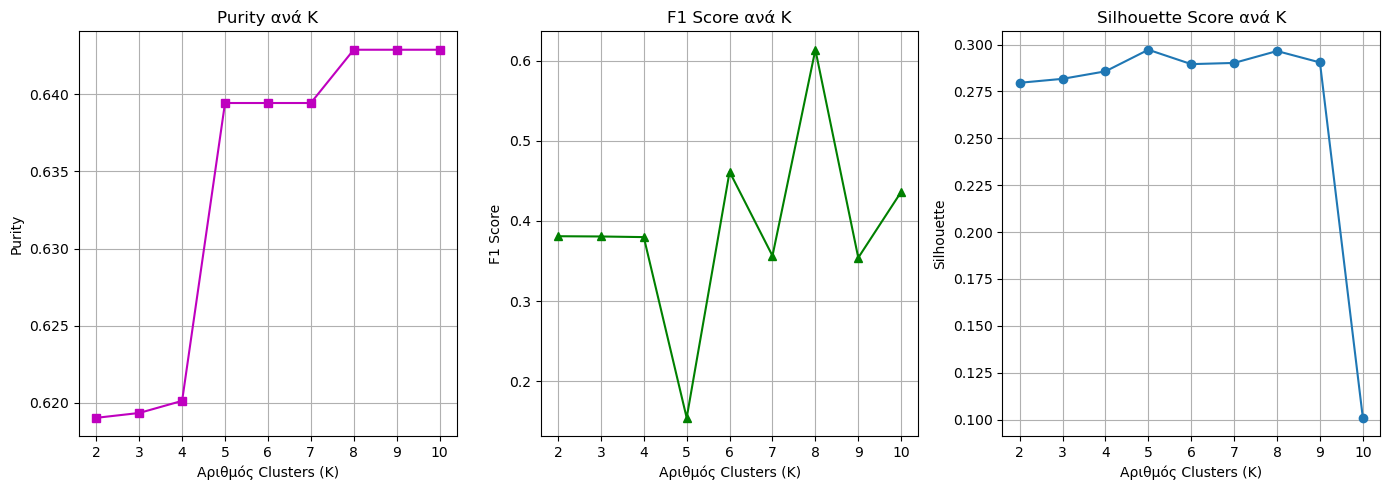


===== Autoencoders + KMeans for M = 3 =====
KMeans (Cosine) | K = 2 | Purity = 0.6226 | F-measure = 0.6226 | Silhouette = 0.0996
KMeans (Cosine) | K = 3 | Purity = 0.6211 | F-measure = 0.2166 | Silhouette = 0.1262
KMeans (Cosine) | K = 4 | Purity = 0.6245 | F-measure = 0.3810 | Silhouette = 0.0764
KMeans (Cosine) | K = 5 | Purity = 0.6209 | F-measure = 0.2365 | Silhouette = 0.0215
KMeans (Cosine) | K = 6 | Purity = 0.6183 | F-measure = 0.0204 | Silhouette = 0.1100
KMeans (Cosine) | K = 7 | Purity = 0.6286 | F-measure = 0.2083 | Silhouette = 0.1207
KMeans (Cosine) | K = 8 | Purity = 0.6245 | F-measure = 0.5248 | Silhouette = 0.1642
KMeans (Cosine) | K = 9 | Purity = 0.6470 | F-measure = 0.0784 | Silhouette = 0.1300
KMeans (Cosine) | K = 10 | Purity = 0.6495 | F-measure = 0.2574 | Silhouette = 0.1183
Best k = 8 with Silhouette Score: 0.16421811613795487


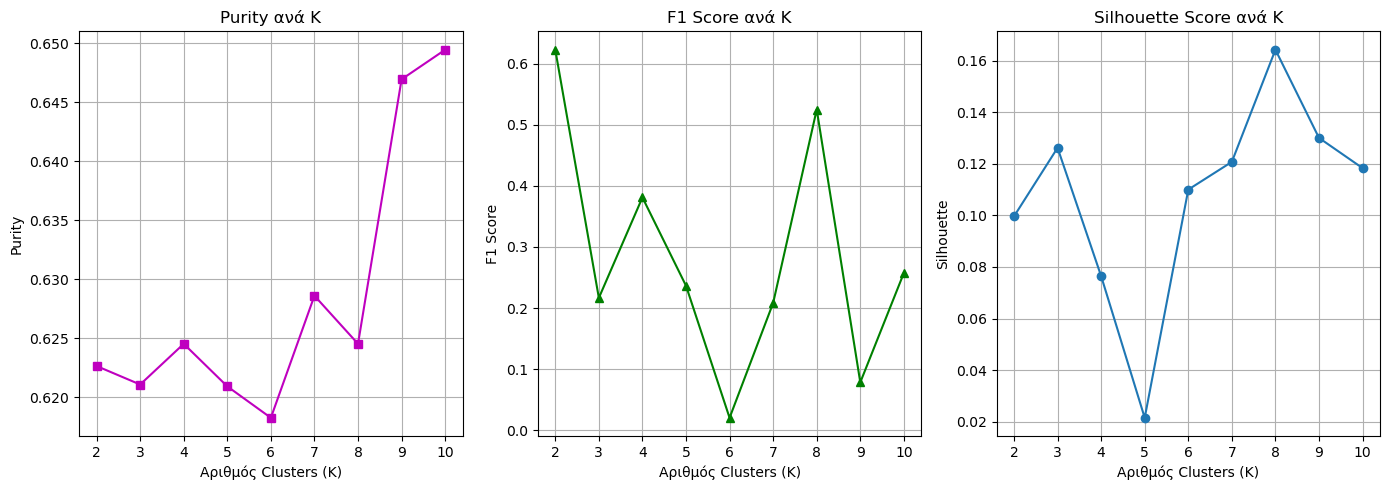


--- Agglomerative Clustering για M = 3 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


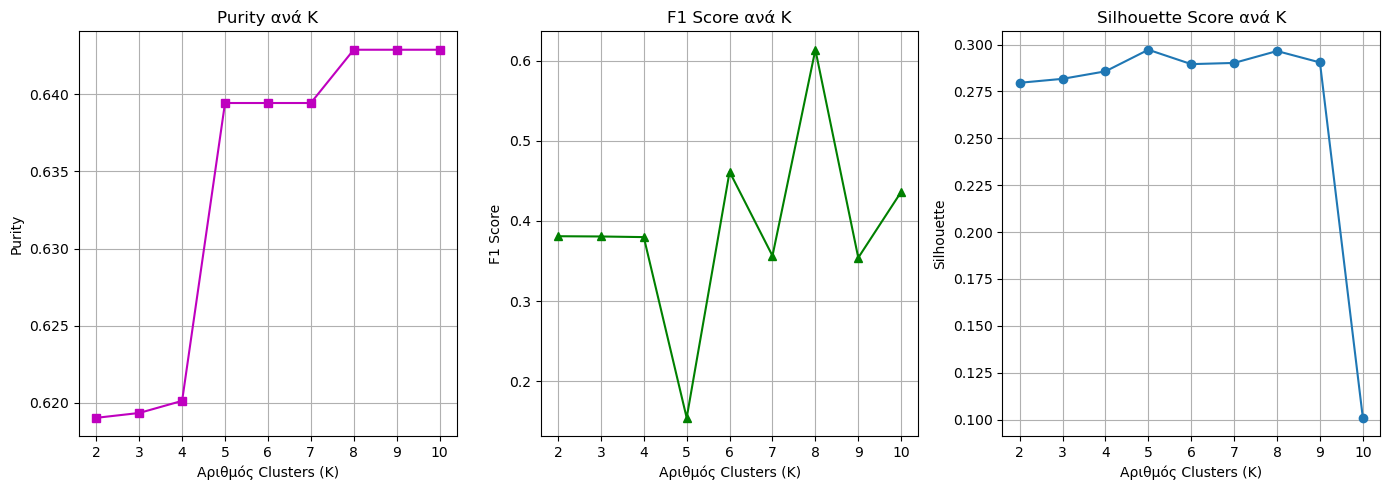


===== Autoencoders + KMeans for M = 5 =====
KMeans (Cosine) | K = 2 | Purity = 0.5830 | F-measure = 0.5830 | Silhouette = 0.1431
KMeans (Cosine) | K = 3 | Purity = 0.6104 | F-measure = 0.1336 | Silhouette = 0.2130
KMeans (Cosine) | K = 4 | Purity = 0.5323 | F-measure = 0.4886 | Silhouette = 0.4141
KMeans (Cosine) | K = 5 | Purity = 0.6184 | F-measure = 0.1990 | Silhouette = 0.1008
KMeans (Cosine) | K = 6 | Purity = 0.6517 | F-measure = 0.3469 | Silhouette = 0.2904
KMeans (Cosine) | K = 7 | Purity = 0.6099 | F-measure = 0.1761 | Silhouette = 0.0933
KMeans (Cosine) | K = 8 | Purity = 0.6413 | F-measure = 0.3112 | Silhouette = 0.1215
KMeans (Cosine) | K = 9 | Purity = 0.6452 | F-measure = 0.2608 | Silhouette = 0.1316
KMeans (Cosine) | K = 10 | Purity = 0.6245 | F-measure = 0.1771 | Silhouette = 0.1099
Best k = 4 with Silhouette Score: 0.41410493095124556


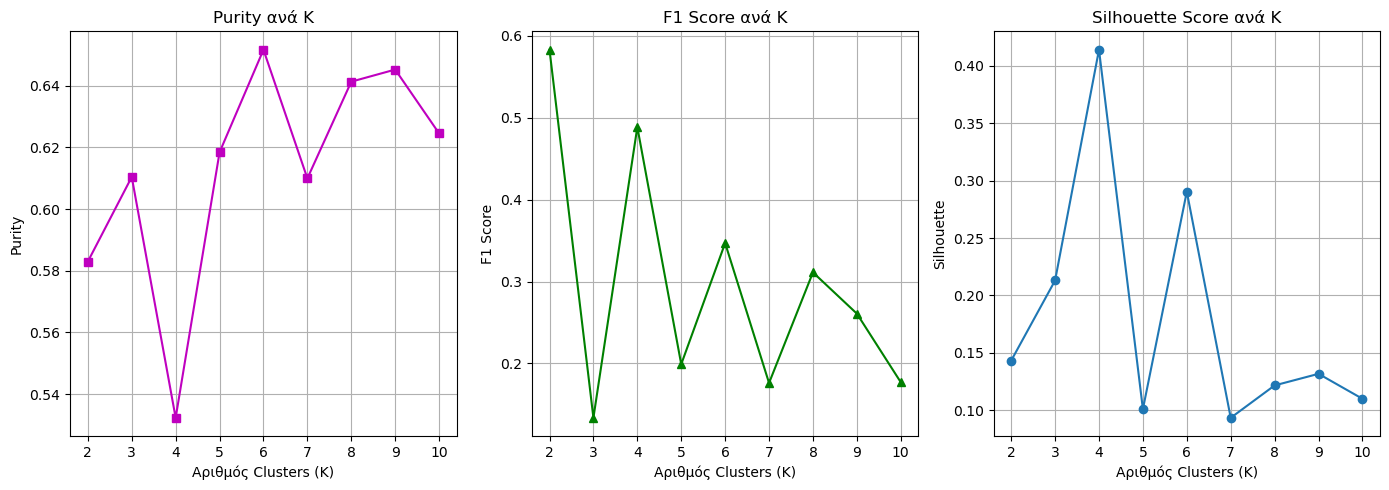


--- Agglomerative Clustering για M = 5 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


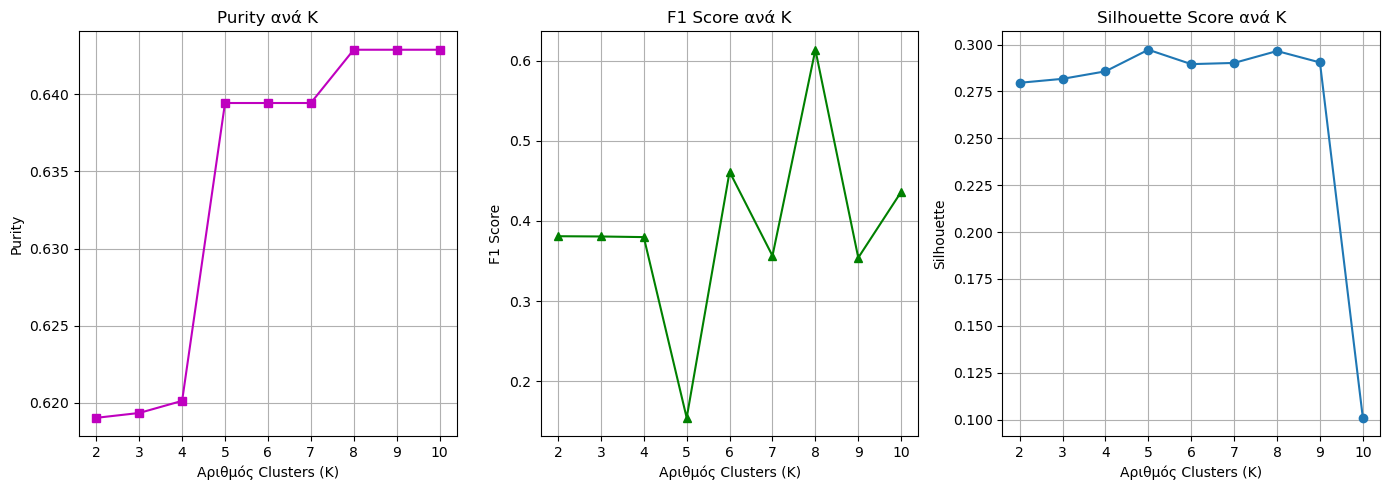


===== Autoencoders + KMeans for M = 10 =====
KMeans (Cosine) | K = 2 | Purity = 0.5831 | F-measure = 0.4169 | Silhouette = 0.2073
KMeans (Cosine) | K = 3 | Purity = 0.5323 | F-measure = 0.5025 | Silhouette = 0.3897
KMeans (Cosine) | K = 4 | Purity = 0.6523 | F-measure = 0.4098 | Silhouette = 0.1883
KMeans (Cosine) | K = 5 | Purity = 0.6432 | F-measure = 0.3427 | Silhouette = 0.3187
KMeans (Cosine) | K = 6 | Purity = 0.6452 | F-measure = 0.2561 | Silhouette = 0.1008
KMeans (Cosine) | K = 7 | Purity = 0.6165 | F-measure = 0.2869 | Silhouette = 0.0975
KMeans (Cosine) | K = 8 | Purity = 0.6501 | F-measure = 0.1283 | Silhouette = 0.1240
KMeans (Cosine) | K = 9 | Purity = 0.6510 | F-measure = 0.2762 | Silhouette = 0.1073
KMeans (Cosine) | K = 10 | Purity = 0.6473 | F-measure = 0.1477 | Silhouette = 0.1336
Best k = 3 with Silhouette Score: 0.3896948029841744


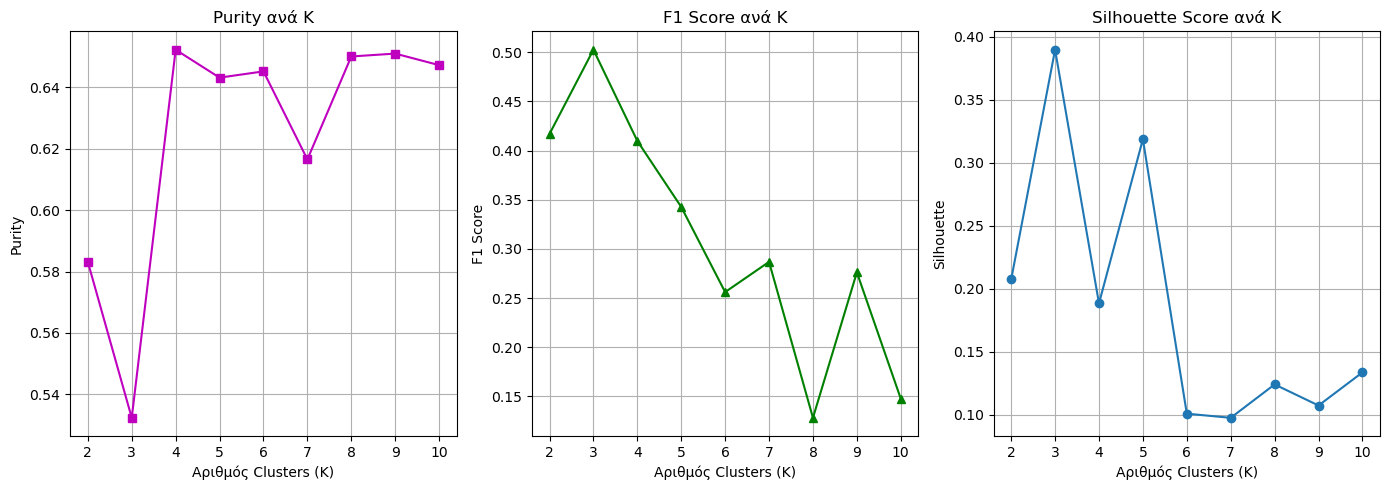


--- Agglomerative Clustering για M = 10 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


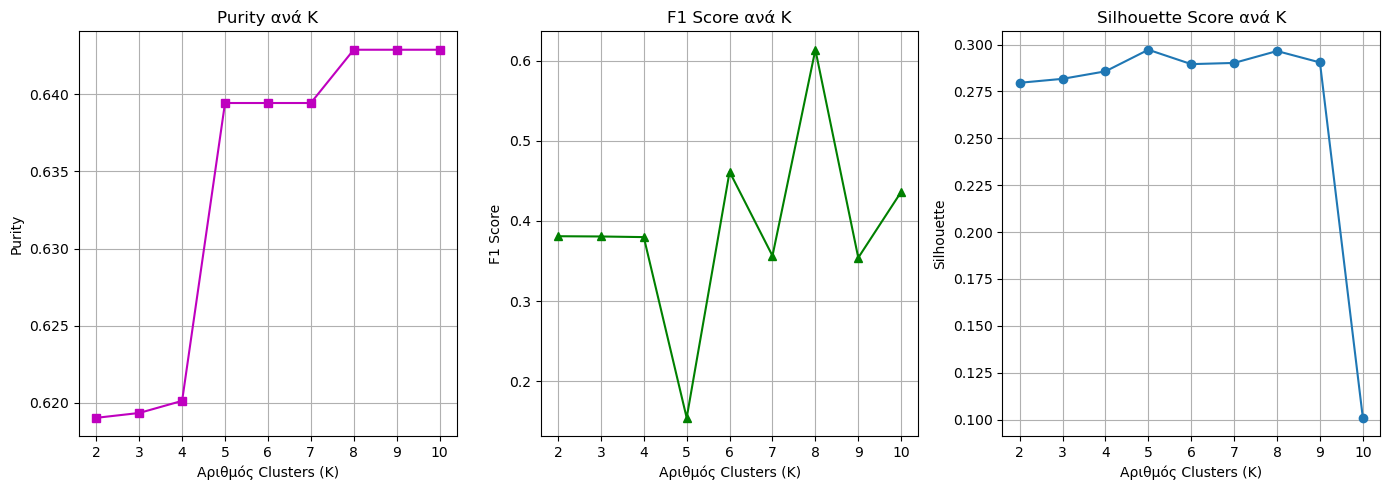


===== Autoencoders + KMeans for M = 20 =====
KMeans (Cosine) | K = 2 | Purity = 0.6208 | F-measure = 0.3792 | Silhouette = 0.2840
KMeans (Cosine) | K = 3 | Purity = 0.5976 | F-measure = 0.5108 | Silhouette = 0.0985
KMeans (Cosine) | K = 4 | Purity = 0.6184 | F-measure = 0.4642 | Silhouette = 0.0868
KMeans (Cosine) | K = 5 | Purity = 0.6380 | F-measure = 0.0402 | Silhouette = 0.1961
KMeans (Cosine) | K = 6 | Purity = 0.6355 | F-measure = 0.1873 | Silhouette = 0.1001
KMeans (Cosine) | K = 7 | Purity = 0.6534 | F-measure = 0.1829 | Silhouette = 0.0916
KMeans (Cosine) | K = 8 | Purity = 0.6350 | F-measure = 0.2916 | Silhouette = 0.1323
KMeans (Cosine) | K = 9 | Purity = 0.6272 | F-measure = 0.1659 | Silhouette = 0.1011
KMeans (Cosine) | K = 10 | Purity = 0.6454 | F-measure = 0.2952 | Silhouette = 0.1148
Best k = 2 with Silhouette Score: 0.28402303272586393


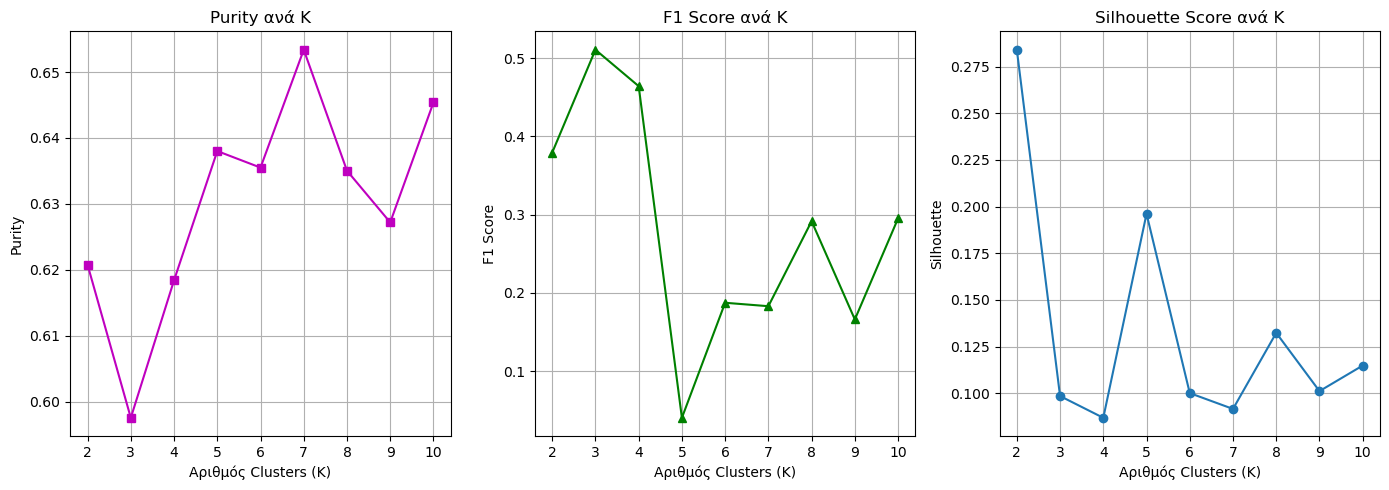


--- Agglomerative Clustering για M = 20 ---
Agglomerative | K = 2 | Purity = 0.6190 | F-measure = 0.3810 | Silhouette = 0.2796
Agglomerative | K = 3 | Purity = 0.6194 | F-measure = 0.3806 | Silhouette = 0.2817
Agglomerative | K = 4 | Purity = 0.6201 | F-measure = 0.3799 | Silhouette = 0.2857
Agglomerative | K = 5 | Purity = 0.6394 | F-measure = 0.1543 | Silhouette = 0.2973
Agglomerative | K = 6 | Purity = 0.6394 | F-measure = 0.4614 | Silhouette = 0.2896
Agglomerative | K = 7 | Purity = 0.6394 | F-measure = 0.3565 | Silhouette = 0.2902
Agglomerative | K = 8 | Purity = 0.6429 | F-measure = 0.6137 | Silhouette = 0.2966
Agglomerative | K = 9 | Purity = 0.6429 | F-measure = 0.3541 | Silhouette = 0.2905
Agglomerative | K = 10 | Purity = 0.6429 | F-measure = 0.4363 | Silhouette = 0.1010
Best k = 5 with Silhouette Score: 0.2972553291121858


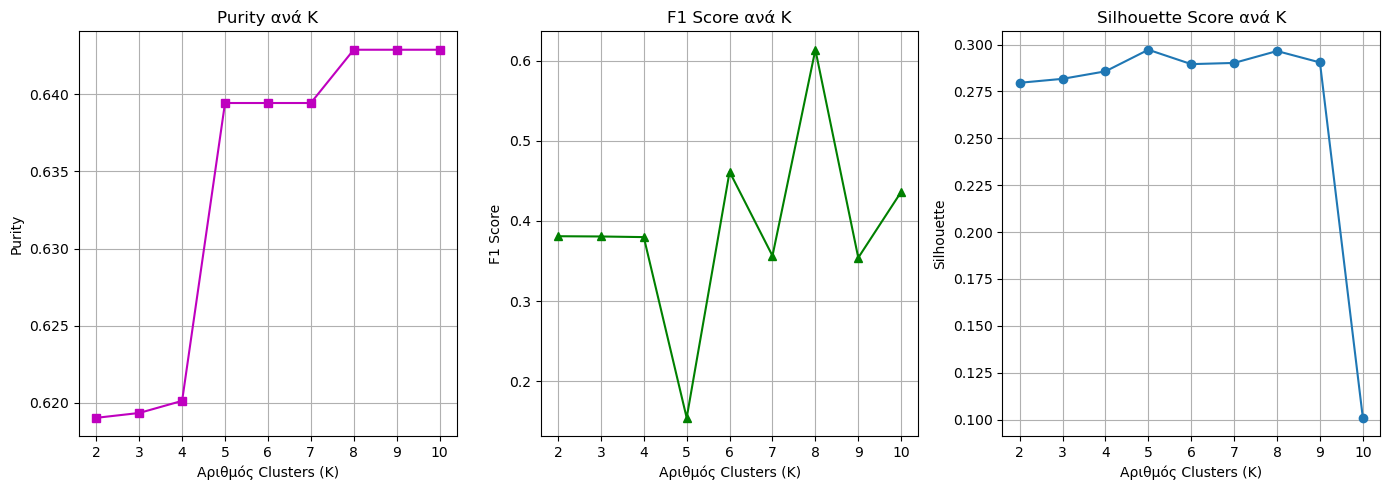

In [33]:
#Autoencoder gia M=2,3,5,10,20

M_values= [2,3,5,10,20]

for M in M_values:
    print(f"\n===== Autoencoders + KMeans for M = {M} =====")

    

    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    best_k = None

    for k in range(2,11):

        #Ευκλίδεια Απόσταση
        kmeans_model= KMeans(n_clusters=k, n_init="auto")
        kmeans_model.fit(x_reduced)
        labels= kmeans_model.labels_

        #υπολογισμος Purity
        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)

        #υπολογισμος F-measure
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        #υπολογισμος Silhoutte
        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            best_k = k

        print(f"KMeans (Cosine) | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()


    #Agglomerative Clustering
    print(f"\n--- Agglomerative Clustering για M = {M} ---")
    silhouette_list = []
    purity_list = []
    f1score_list = []
    best_score = -1
    agg_best_k = None

    for k in range(2,11):
        
        agg = AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage="ward")
        labels = agg.fit_predict(x_reduced) 

        contingency = metrics.cluster.contingency_matrix(y, labels)
        purity = np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)
        purity_list.append(purity)
        
        f1 = f1_score(y,labels,average="micro")
        f1score_list.append(f1)

        silhouette = silhouette_score(x_reduced,labels)
        silhouette_list.append(silhouette)

        if silhouette > best_score:
            best_score = silhouette
            agg_best_k = k

        print(f"Agglomerative | K = {k} | Purity = {purity:.4f} | F-measure = {f1:.4f} | Silhouette = {silhouette:.4f}")
    
    print("Best k =", agg_best_k, "with Silhouette Score:", best_score)

    k_values = range(2,11)
    plt.figure(figsize=(14,5))


    # Διάγραμμα Purity
    plt.subplot(1,3,1)
    plt.plot(k_values, purity_list, marker='s', color='m')
    plt.title("Purity ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Purity")
    plt.grid(True)

    # Diagramma F-Measure
    plt.subplot(1, 3, 2)
    plt.plot(k_values, f1score_list, marker='^', color='g')
    plt.title("F1 Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("F1 Score")
    plt.grid(True)        

    # Diagramma Silhouette
    plt.subplot(1, 3, 3)
    plt.plot(k_values, silhouette_list, marker='o')
    plt.title("Silhouette Score ανά K")
    plt.xlabel("Αριθμός Clusters (K)")
    plt.ylabel("Silhouette")
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()